# Assignment 3 - Neighbourhood-based metaheuristics for the Set Covering Problem (SCP)

**Course:** Heuristic Optimization &nbsp;|&nbsp; **Deadline:** 15/10/26

**Task.** Design and implement **two neighbourhood-based metaheuristics** for the SCP - we choose **simulated annealing (SA)** and **tabu search (TS)** -
by deciding the main features that these methods require, and design a **comprehensive set of computational experiments** that shows the influence of
the **parameters and building blocks** on the **effectiveness** (solution quality) and **efficiency** (computation effort) of the algorithms.
The results are interpreted and supported by statistical tests; the raw data used for the tests are exported to a spreadsheet and a text file (Section 15).

**Plan (built on the notebooks of Assignments 1 and 2).**

1. Initial solution: the greedy constructive heuristic **CH3**.
2. Redundancy elimination **RE** - on the initial solution and (building block to be tested) **after every move**.
3. The metaheuristics **SA** and **TS** on the *drop-and-repair* neighbourhood of Assignment 2.
4. Experiments on parameters and building blocks, then a final comparison **TS vs. SA vs. the local search (FI, BI) of Assignment 2**.

| Step | Content |
|---|---|
| 1 | **Theory** - escaping local optima: stochastic hill-climber, simulated annealing, tabu search, VNS and GRASP; experimental methodology |
| 2-4 | Data, solution state, initial solution CH3 + RE *(recap of Assignments 1 and 2)* |
| 5 | The neighbourhood (move) and its building blocks |
| 6 | **Simulated annealing**: decisions, implementation, test |
| 7 | **Tabu search**: decisions, implementation, test |
| 8 | Local search baselines FI / BI from Assignment 2 |
| 9 | **Experimental design** |
| 10-13 | **Experiments:** SA parameters, TS parameters, building blocks (incl. RE on every step), computation budget |
| 14 | **Final comparison** TS vs. SA vs. FI / BI with statistical tests |
| 15 | Raw data export (spreadsheet + text file) |
| 16 | **Interpretation and conclusions** |

Style rules as before: only plain functions (no classes), a solution state is a dictionary of arrays, and every change of the state is **incremental**.

## 1. Theory

### 1.1 Why escape local optima?
Traditional problem-solving strategies either **guarantee** the global optimum but are too expensive for realistic instances, or they are fast but **get stuck in local optima**.
Since there is almost no chance to speed up exact methods, we design algorithms that are **able to escape local optima**.

A **local search** (Assignment 2) moves to a better neighbour while one exists and stops in a *local optimum* of the neighbourhood $N$:

```
x = initial solution
while improve(x) != 'no':  x = improve(x)           # improve(x) returns y in N(x) better than x
return x                                            # a local optimum
```

The simplest ways out of a local optimum:

* **Iterated hill-climber / restarts:** repeat the local search from new starting points; restarting is the *only* way to leave a local optimum.
* **Stochastic hill-climber:** pick **one** random neighbour $v_n$ of the current point $v_c$ and **accept** it with a probability that depends on the quality difference,
  for minimisation e.g. $p = \dfrac{1}{1+e^{(f(v_n)-f(v_c))/T}}$. A worse neighbour can be accepted; the parameter $T$ is **constant**.
  Large $T$: $p\approx 0.5$ for every neighbour (random walk); small $T$: $p\approx 0$ for worse neighbours (hill-climber).

### 1.2 Simulated annealing (SA)
SA is the stochastic hill-climber with a **temperature $T$ that changes during the run**: start with a high $T$ (almost random search) and **cool down** gradually, so that
the final phase behaves like an ordinary hill-climber. A better neighbour is **always** accepted; a worse one with the **Metropolis probability**

$$p(\text{accept } x') = \exp\!\left(-\frac{f(x')-f(x)}{T}\right) \quad\text{for } f(x')>f(x).$$

*Analogy (annealing of metals/crystals):* heat to a molten state, then reduce the temperature slowly; cooling too fast freezes irregularities (high-energy defects) into the structure.

| Physical system | Optimisation problem |
|---|---|
| state | feasible solution |
| energy | evaluation (cost) function |
| ground state | optimal solution |
| temperature | control parameter $T$ |

**Minimisation pseudo-code (lecture):**
```
x = initial solution; x* = x; T = initial_temperature()
repeat
    for k = 1 .. L:                                  # L = length of the epoch (iterations at constant T)
        x' = random_neighbour(x)
        if f(x') <= f(x):  x = x';  if f(x') < f*: x* = x'; f* = f(x')
        else:              x = x' with probability exp(-(f(x')-f(x))/T)
    update(L, T)                                     # geometric cooling  T <- alpha * T  (0 < alpha < 1)
until stop criterion
```

**Problem-specific decisions:** what is a solution, what are the neighbours, what is the cost, how is the initial solution generated.
**Generic SA decisions:** the initial temperature $T_0$ (rule of thumb: a *bad* move is accepted with a probability of 50 % at the start), the cooling scheme $g(T,t)$
(geometric: $T_{t+1}=\alpha T_t$), the epoch length $L$, the termination condition (a fixed, "long" number of iterations) and the halting criterion (e.g. iterations without change).
If the cooling is too fast the search freezes in a poor local optimum; if it is very slow the run needs many iterations.

### 1.3 Tabu search (TS)
TS is *basically deterministic* (unlike SA) and escapes local optima with a **memory** that forbids returning to recently visited solutions.
In every iteration the (sub)neighbourhood of the current solution is evaluated and the **best non-tabu neighbour is taken - even if it is worse** than the current solution; this lets the search climb out of a local optimum,
and the tabu status prevents it from falling straight back.

* **Recency-based (short-term) memory.** Not the solutions but the **modifications (attributes)** are recorded. If a modification is made in iteration $t$, its reverse is tabu for the **tenure** (list size) of the next iterations,
  e.g. a vector $M(i)=t$ stores the last iteration in which element $i$ was changed; element $i$ is tabu while $M(i) > t-\text{tenure}$.
  Tenure too small: cycling, premature convergence; too large: too many moves forbidden, worse final solution; a **dynamic (variable) tenure** is an option.
* **Aspiration criterion.** A tabu move is too restrictive when it leads to an excellent solution: a tabu neighbour that is **better than the best solution found so far** is accepted anyway.
* **Frequency-based (long-term) memory.** Counts how often modifications were made over a long horizon; it diversifies the search by **penalising** over-used modifications
  ($\text{eval}(x')-\text{penalty}(x')$ in the lecture's maximisation form) or by favouring under-represented ones.
* **Sub-neighbourhood.** For large neighbourhoods only a sample $V'(x)$ of the neighbours is evaluated per iteration.

**Minimisation pseudo-code (lecture):**
```
x = initial solution; x* = x; F* = F(x)
repeat
    V'(x) = sub_neighbourhood(x); Fbar = infinity
    for all x' in V'(x):
        if F(x') < Fbar:
            m' = modification(x, x')
            if m' not in tabu_list  or  (m' in tabu_list and F(x') < F*):      # aspiration
                xbar = x'; mbar = m'; Fbar = F(x')
    x = xbar; insert_tabu_list(mbar)
    if Fbar < F*:  x* = xbar; F* = Fbar
until stop criterion
```
**Generic TS decisions:** sub-neighbourhood size and how to sample it; tabu status of solutions or of modifications and which attributes are stored; memory needed and the efficiency of insertion / removal / lookup;
the tabu list size (fixed or dynamic); long-term memory; when to diversify; how to stop.

### 1.4 Other methods of the lecture (not implemented here, but related to our building blocks)
* **Variable neighbourhood search (VNS):** systematically change the neighbourhood: *shake* (random point in the $k$-th neighbourhood), improve it with a local search / VND, move if better and restart with $k=1$, else $k\leftarrow k+1$.
  Our *drop-and-repair* neighbourhood with several dropped sets would be a natural shaking step.
* **GRASP:** repeated greedy *randomised* construction (choose the next element randomly from a **restricted candidate list** of the best candidates) followed by a local search.
  We use exactly this idea as a **building block of the move**: the repair step may pick its set randomly from the `rcl` best candidates instead of the single best one.

### 1.5 Methodology: how do we measure the influence of parameters and building blocks?
* **Effectiveness** = solution quality: the **percentage deviation** from the best known solution, $\text{dev}=100\,(f-f_{best})/f_{best}$, averaged over instances.
  **Efficiency** = effort: the **number of evaluated neighbours** (machine independent, the *budget*) and the CPU time.
  We compare algorithms at an **equal budget** and look at **anytime** behaviour (best-so-far quality against the number of evaluations).
* **Parameters** are studied with **factorial designs** (grids over several parameters) and one-factor-at-a-time variations around a reference configuration; the instance is a **blocking factor**
  (instances differ in difficulty, so all configurations are applied to the same instances and the same seeds - a *paired* design, the starting solution is identical for all of them).
* **Statistics:** ANOVA with the instance as a block and the **partial $\eta^2$** as effect size (how much of the variation a parameter explains);
  for rankings the non-parametric **Friedman test** over the instances with **Wilcoxon signed-rank** tests against a reference and **Holm's correction** for multiple comparisons.
* **Overfitting:** parameters are tuned on a **tuning subset of instances** with their own seeds; the final comparison uses **all 42 instances** and new seeds, and we also report the result on the instances that were *not* used for tuning.

## 2. Imports and data

In [1]:
import os
os.environ.setdefault("OMP_NUM_THREADS", "1")          # one numpy thread per worker process
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
import random
import time
import itertools
import multiprocessing as mp
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 200)

DATA = Path("SCP-Instances 2")   # folder with the OR-Library SCP files
BUDGET = 3000                    # evaluated neighbours per run (the unit of computational effort)
N_WORKERS = 9                    # parallel worker processes for the parameter studies
COL = {"SA": "#e8873a", "TS": "#1f6f78", "FI": "#9aa0a6", "BI": "#5b6b70", "start": "#c9ced3"}

### Instance file format (OR-Library)
```
m n                      number of elements (rows) and sets (columns)
c_1 ... c_n              cost of every set
for every element i:     k_i, then the k_i sets (1-based) that cover element i
```
We keep both directions of the incidence relation, because the incremental updates need both:

* `rows_of_col[j]` - elements covered by set `j`
* `cols_of_row[e]` - sets that cover element `e`

In [2]:
def invert(lists, size):
    # 'lists[i]' holds items in range(size); return, for every item, the list of i that contain it
    out = [[] for _ in range(size)]
    for i, items in enumerate(lists):
        for x in items:
            out[x].append(i)
    return [np.array(o, dtype=np.int64) for o in out]


def build_instance(name, cost, rows_of_col, m):
    # an instance is a plain dictionary
    return {"name": name, "m": m, "n": len(cost), "cost": np.array(cost, dtype=float),
            "rows_of_col": [np.array(r, dtype=np.int64) for r in rows_of_col],
            "cols_of_row": invert(rows_of_col, m)}


def read_instance(path):
    tok = np.array(Path(path).read_text().split(), dtype=np.int64)
    m, n = tok[0], tok[1]
    cost = tok[2:2 + n]
    pos = 2 + n
    cols_of_row = []
    for _ in range(m):
        k = tok[pos]
        cols_of_row.append(tok[pos + 1:pos + 1 + k] - 1)      # to 0-based
        pos += 1 + k
    assert pos == len(tok), "unexpected data at the end of the file"
    return build_instance(Path(path).stem, cost, invert(cols_of_row, n), m)

In [3]:
def natural_key(p):
    # scp42 < scp51 < scpa1 < scpa2 ...
    return p.stem.rstrip("0123456789"), int(p.stem[len(p.stem.rstrip("0123456789")):])

files = sorted(DATA.glob("scp*.txt"), key=natural_key)
instances = [read_instance(f) for f in files]

pd.DataFrame([{"instance": i["name"], "elements m": i["m"], "sets n": i["n"],
               "avg cost": i["cost"].mean()} for i in instances]).set_index("instance").T

instance,scp42,scp43,scp44,scp45,scp46,scp47,scp48,scp49,scp51,scp52,scp53,scp54,scp55,scp56,scp57,scp58,scp59,scp61,scp62,scp63,scp64,scp65,scpa1,scpa2,scpa3,scpa4,scpa5,scpb1,scpb2,scpb3,scpb4,scpb5,scpc1,scpc2,scpc3,scpc4,scpc5,scpd1,scpd2,scpd3,scpd4,scpd5
elements m,200.00,200.000,200.000,200.00,200.000,200.000,200.000,200.000,200.0000,200.000,200.0000,200.000,200.0000,200.0000,200.0000,200.0000,200.000,200.00,200.00,200.000,200.000,200.00,300.000000,300.000000,300.000,300.000000,300.000,300.00,300.000,300.000000,300.000,300.000000,400.00000,400.00000,400.00000,400.0000,400.00000,400.0000,400.0000,400.0000,400.0000,400.0000
sets n,1000.00,1000.000,1000.000,1000.00,1000.000,1000.000,1000.000,1000.000,2000.0000,2000.000,2000.0000,2000.000,2000.0000,2000.0000,2000.0000,2000.0000,2000.000,1000.00,1000.00,1000.000,1000.000,1000.00,3000.000000,3000.000000,3000.000,3000.000000,3000.000,3000.00,3000.000,3000.000000,3000.000,3000.000000,4000.00000,4000.00000,4000.00000,4000.0000,4000.00000,4000.0000,4000.0000,4000.0000,4000.0000,4000.0000
avg cost,49.83,50.176,50.264,49.79,51.277,48.933,52.261,51.932,50.6395,51.557,49.2755,49.488,50.7675,51.5235,50.6225,50.7845,50.662,50.05,49.83,50.176,50.264,49.79,50.587333,50.982333,49.717,50.669333,49.867,50.63,50.652,50.988667,49.563,50.466667,50.88775,49.81325,51.09775,50.2625,50.73425,50.8935,49.9495,51.0505,50.2535,50.5205


## 3. Solution state with incremental updates *(recap of Assignments 1 and 2)*

A (partial) solution is stored together with everything the heuristics need to make their next decision:

| field | meaning | why |
|---|---|---|
| `in_sol[j]` | set `j` is selected | the solution itself |
| `cnt[e]` | how many selected sets cover element `e` | `cnt[e]==0` uncovered; a set is *redundant* iff all its elements have `cnt>=2` |
| `new_cov[j]` | number of **uncovered** elements set `j` still contains | the **dynamic** score; `new_cov[j]==0` means `j` is not a candidate (adding it would be redundant) |
| `uncovered`, `pos` | list of uncovered elements with O(1) insert / delete | to pick an uncovered element quickly |
| `cost` | total cost of the selected sets | the evaluation function value |
| `log` | list of performed `add`/`remove` operations | lets the local search **undo** a tried move without copying the state |

**Incremental update rules** (this is the core of the whole notebook):

* **add set `j`:** for every element `e` of `j` with `cnt[e]==0` (it becomes covered): remove `e` from `uncovered` and decrease `new_cov[s]` by 1 for **every set `s` that contains `e`**.
  Then `cnt[e]+=1` for all elements of `j`, and `cost += w_j`.
* **remove set `j`:** `cnt[e]-=1` for all elements of `j`; every element whose count drops to 0 becomes uncovered again,
  so add it to `uncovered` and increase `new_cov[s]` by 1 for every set `s` containing it. `cost -= w_j`.

`remove` is the exact inverse of `add`. Only the elements of `j` and the sets touching them are visited - the cost of one update is tiny compared with recomputing all scores.

In [4]:
def new_state(inst):
    # empty partial solution: nothing covered, every set could still cover all of its elements
    return {"in_sol": np.zeros(inst["n"], dtype=bool),
            "cnt": np.zeros(inst["m"], dtype=np.int64),
            "new_cov": np.array([len(r) for r in inst["rows_of_col"]], dtype=np.int64),
            "uncovered": list(range(inst["m"])),
            "pos": list(range(inst["m"])),          # pos[e] = index of e inside 'uncovered'
            "cost": 0.0,
            "log": []}


def mark_covered(st, e):
    # O(1) removal from the uncovered list: move the last element into e's slot
    i, last = st["pos"][e], st["uncovered"][-1]
    st["uncovered"][i] = last
    st["pos"][last] = i
    st["uncovered"].pop()


def mark_uncovered(st, e):
    st["pos"][e] = len(st["uncovered"])
    st["uncovered"].append(e)


def add_set(inst, st, j, log=True):
    rows = inst["rows_of_col"][j]
    for e in rows[st["cnt"][rows] == 0]:                 # elements that become covered now
        mark_covered(st, e)
        st["new_cov"][inst["cols_of_row"][e]] -= 1       # every set containing e has one uncovered element less
    st["cnt"][rows] += 1
    st["in_sol"][j] = True
    st["cost"] += inst["cost"][j]
    if log:
        st["log"].append(("add", j))


def remove_set(inst, st, j, log=True):
    rows = inst["rows_of_col"][j]
    st["cnt"][rows] -= 1
    for e in rows[st["cnt"][rows] == 0]:                 # elements that become uncovered now
        mark_uncovered(st, e)
        st["new_cov"][inst["cols_of_row"][e]] += 1
    st["in_sol"][j] = False
    st["cost"] -= inst["cost"][j]
    if log:
        st["log"].append(("remove", j))


def undo_to(inst, st, mark):
    # revert all operations after position 'mark' of the log (newest first)
    while len(st["log"]) > mark:
        op, j = st["log"].pop()
        if op == "add":
            remove_set(inst, st, j, log=False)
        else:
            add_set(inst, st, j, log=False)


def is_redundant(inst, st, j):
    # selected set j is redundant iff every element it covers is also covered by another selected set
    return bool(np.all(st["cnt"][inst["rows_of_col"][j]] >= 2))


def selected_sets(st):
    return np.flatnonzero(st["in_sol"])

### Independent check of the bookkeeping
Incremental code is easy to get subtly wrong, so we add a function that rebuilds everything **from scratch** from the list of selected sets
and compares it with the incrementally maintained values. It is called after every run in the experiments.

In [5]:
def check_state(inst, st, complete=True, minimal=False):
    # recompute counts, uncovered elements, new_cov and cost from scratch and compare
    sel = selected_sets(st)
    cnt = np.zeros(inst["m"], dtype=np.int64)
    for j in sel:
        cnt[inst["rows_of_col"][j]] += 1
    assert (cnt == st["cnt"]).all(), "cnt out of sync"
    assert set(np.flatnonzero(cnt == 0)) == set(st["uncovered"]), "uncovered list out of sync"
    new_cov = np.array([np.sum(cnt[r] == 0) for r in inst["rows_of_col"]])
    assert (new_cov == st["new_cov"]).all(), "new_cov out of sync"
    assert abs(inst["cost"][sel].sum() - st["cost"]) < 1e-6, "cost out of sync"
    if complete:
        assert (cnt > 0).all(), "not a cover"
    if minimal:
        assert not any(is_redundant(inst, st, j) for j in sel), "a redundant set is left"
    return st["cost"]

For the fast redundancy elimination below we also keep the **incidence matrix** $A$ ($n\times m$, `A[j, e] = 1` iff set `j` contains element `e`) of every instance as a sparse matrix.

In [6]:
def add_incidence(inst):
    rows = np.concatenate([np.full(len(r), j) for j, r in enumerate(inst["rows_of_col"])])
    cols = np.concatenate(inst["rows_of_col"])
    inst["A"] = sp.csr_matrix((np.ones(len(rows), dtype=np.int32), (rows, cols)), shape=(inst["n"], inst["m"]))
    return inst

instances = [add_incidence(i) for i in instances]
byname = {i["name"]: i for i in instances}
print(len(instances), "instances, e.g.", instances[0]["name"], "A =", instances[0]["A"].shape, "nnz =", instances[0]["A"].nnz)

42 instances, e.g. scp42 A = (1000, 200) nnz = 3982


## 4. Initial solution: CH3, then redundancy elimination

**CH3** is the dynamic greedy heuristic of Chvatal: in every step add the set with the lowest cost per still-uncovered element, $w_j/\text{new\_cov}_j$ (ties broken randomly).
`greedy_complete` completes *any* partial solution with this rule - the same function is later the **repair step** of the neighbourhood.
Two optional arguments make it a building block for the metaheuristics:

* `banned` - a boolean array of sets that may **not** be added (the tabu sets of TS) and `forbid` - one set that may not be added (the set just dropped by the move). If *every* candidate is forbidden the restrictions are lifted, so the cover always stays feasible.
* `rcl` - the size of the **restricted candidate list** (GRASP idea): the set is drawn at random among the `rcl` best ones; `rcl = 1` is the plain greedy rule.

In [7]:
def greedy_complete(inst, st, rng, banned=None, forbid=-1, rcl=1):
    # complete ANY partial solution with the dynamic greedy ratio rule (cost / newly covered elements)
    while st["uncovered"]:
        ok = st["new_cov"] > 0                                   # dynamic candidate list
        cand_ok = ok & ~banned if banned is not None else ok.copy()
        if forbid >= 0:
            cand_ok[forbid] = False
        if not cand_ok.any():
            cand_ok = ok                                         # everything forbidden: lift the restrictions
        cand = np.flatnonzero(cand_ok)
        ratio = inst["cost"][cand] / st["new_cov"][cand]
        if rcl <= 1 or len(cand) <= 1:
            best = cand[ratio == ratio.min()]
            j = int(best[rng.randrange(len(best))])              # greedy, random tie-breaking
        else:
            r = min(rcl, len(cand))
            top = np.argpartition(ratio, r - 1)[:r]              # the r best candidates ...
            j = int(cand[top[rng.randrange(r)]])                 # ... one of them at random (GRASP)
        add_set(inst, st, j)
    return st


def ch3(inst, rng):
    return greedy_complete(inst, new_state(inst), rng)


def ch1(inst, rng):
    # random uncovered element -> random set covering it (only used to test the influence of the initial solution)
    st = new_state(inst)
    while st["uncovered"]:
        e = st["uncovered"][rng.randrange(len(st["uncovered"]))]
        cols = inst["cols_of_row"][e]
        add_set(inst, st, int(cols[rng.randrange(len(cols))]))
    return st

### Redundancy elimination (RE) - fast version
RE removes selected sets whose elements are all covered by other selected sets, most expensive first (see Assignment 1: one pass is enough, because coverage counts only decrease).
In the metaheuristics RE is called **after every move**, so it has to be cheap. The previous version scanned *all* selected sets in Python.
The fast version finds **all redundant sets with one sparse matrix-vector product**: with $\text{low}_e=1$ iff `cnt[e] < 2`, a selected set $j$ is redundant iff $(A\cdot \text{low})_j = 0$.
Only these candidates are then processed (in the same order as before, re-checking each one), so the result is **identical** to the slow version - we verify this below.

In [8]:
def redundancy_elimination(inst, st, rng):
    low = (st["cnt"] < 2).astype(np.int32)                          # elements covered at most once
    red = list(np.flatnonzero(st["in_sol"] & (inst["A"] @ low == 0)))   # selected sets without any "lonely" element
    if not red:
        return 0
    rng.shuffle(red)                                                # random order ...
    red.sort(key=lambda j: -inst["cost"][j])                        # ... then by decreasing cost (stable -> random ties)
    removed = 0
    for j in red:
        if is_redundant(inst, st, j):                               # an earlier removal may have made j necessary
            remove_set(inst, st, j)
            removed += 1
    return removed


def redundancy_elimination_slow(inst, st, rng):
    # the version of Assignments 1 and 2 (scans every selected set); kept only for the equivalence test
    sel = list(selected_sets(st))
    rng.shuffle(sel)
    sel.sort(key=lambda j: -inst["cost"][j])
    removed = 0
    for j in sel:
        if is_redundant(inst, st, j):
            remove_set(inst, st, j)
            removed += 1
    return removed

In [9]:
# Test: same result as the slow version (random order replaced by a fixed one) on random, highly redundant covers;
# and the speed-up for one move evaluation (drop a set, repair, RE, undo)
from types import SimpleNamespace
fixed = SimpleNamespace(shuffle=lambda x: None)
differ = 0
for inst in instances[::6]:
    for seed in range(5):
        rng = random.Random(seed)
        st = ch1(inst, rng)
        a, b = new_state(inst), new_state(inst)
        for j in selected_sets(st):
            add_set(inst, a, int(j)); add_set(inst, b, int(j))
        redundancy_elimination(inst, a, fixed); redundancy_elimination_slow(inst, b, fixed)
        differ += int(not (a["in_sol"] == b["in_sol"]).all())
        check_state(inst, a, minimal=True)
print("covers where the fast and the slow RE differ:", differ, "of", 7 * 5)

inst = byname["scpa1"]; rng = random.Random(1)
st = greedy_complete(inst, new_state(inst), rng); redundancy_elimination(inst, st, rng); st["log"].clear()
sel = [int(j) for j in selected_sets(st)]
for label, re_fn in [("fast RE", redundancy_elimination), ("slow RE", redundancy_elimination_slow)]:
    t0 = time.perf_counter()
    for j in sel * 3:
        mark = len(st["log"]); remove_set(inst, st, j); greedy_complete(inst, st, rng, forbid=j); re_fn(inst, st, rng); undo_to(inst, st, mark)
    print(f"{label}: {1000 * (time.perf_counter() - t0) / (3 * len(sel)):.3f} ms per evaluated neighbour (scpa1)")

covers where the fast and the slow RE differ: 0 of 35
fast RE: 0.069 ms per evaluated neighbour (scpa1)
slow RE: 0.262 ms per evaluated neighbour (scpa1)


### Initial solution = CH3 + RE
Every algorithm of this notebook starts from the **same** solution: CH3 followed by one RE pass, built from `random.Random(seed)`. The random number generator then continues into the metaheuristic,
so with the same seed all algorithms on an instance start from the identical cover (**variance reduction**, paired comparisons).
`kind` selects another start (`"CH3"` without RE, `"CH1+RE"` random) - only used in the study of the building blocks.

In [10]:
def initial_solution(inst, rng, kind="CH3+RE"):
    st = ch1(inst, rng) if kind.startswith("CH1") else ch3(inst, rng)
    if kind.endswith("+RE"):
        redundancy_elimination(inst, st, rng)
    st["log"].clear()
    return st


def read_best(path):
    # 'label cost' per line;  '4.2' -> 'scp42',  '5.10' -> 'scp510',  'A.1' -> 'scpa1'
    best = {}
    for line in Path(path).read_text().splitlines():
        if line.strip():
            label, value = line.split()
            group, number = label.split(".")
            best["scp" + group.lower() + number] = int(value)
    return best


BEST = read_best(DATA / "best_solution.txt")
assert all(i["name"] in BEST for i in instances)

def dev(cost, best):
    return 100.0 * (cost - best) / best

start = []
for inst in instances:
    c3 = ch3(inst, random.Random(1)); c3re = initial_solution(inst, random.Random(1))
    start.append({"instance": inst["name"], "CH3": dev(c3["cost"], BEST[inst["name"]]), "CH3+RE": dev(c3re["cost"], BEST[inst["name"]])})
start = pd.DataFrame(start).set_index("instance")
print("average deviation of the start solution:  CH3 = %.2f %%,  CH3 + RE = %.2f %%" % (start["CH3"].mean(), start["CH3+RE"].mean()))

average deviation of the start solution:  CH3 = 13.05 %,  CH3 + RE = 6.46 %


## 5. The neighbourhood: drop and repair

As in Assignment 2, a **move** takes a selected set $j$ out of the cover and repairs it: for a minimal cover $S$

$$N(S)=\{\,\text{RE}(\text{repair}(S\setminus\{j\})) : j\in S\,\}.$$

Every neighbour is a feasible cover; $|N(S)|$ equals the number of selected sets. Moves are applied **incrementally** (`remove_set` / `add_set`) and undone from the log, the state is never copied.
The move has three **building blocks that we test**: whether RE is applied **after every move** (`re_step`; otherwise only once at the end on the best solution found),
how **random** the repair is (`rcl`), and which sets are **forbidden** in the repair (`banned`, used by tabu search).

**Problem-specific decisions** (common to SA and TS): *solution* = set of selected columns forming a cover; *cost* = sum of the costs; *neighbours* = drop-and-repair as above;
*initial solution* = CH3 + RE.

In [11]:
def apply_move(inst, st, j, rng, banned=None, rcl=1, re_step=True):
    # drop j, repair greedily (j and the banned sets may not come back), optionally remove redundant sets
    remove_set(inst, st, j)
    greedy_complete(inst, st, rng, banned=banned, forbid=j, rcl=rcl)
    if re_step:
        redundancy_elimination(inst, st, rng)


def replay_ops(inst, st, ops):
    for op, j in ops:
        add_set(inst, st, j) if op == "add" else remove_set(inst, st, j)


def restore(inst, sel, rng, re_final):
    # rebuild the state of a stored solution (list of selected sets); RE at the end if it was not applied after every move
    st = new_state(inst)
    for j in sel:
        add_set(inst, st, int(j))
    if re_final:
        redundancy_elimination(inst, st, rng)
    return st

## 6. Simulated annealing

### Decisions

| Decision | Our choice | Parameter |
|---|---|---|
| neighbour | **random** neighbour: a uniformly chosen selected set is dropped and the cover is repaired (+ RE) | `rcl`, `re_step` |
| acceptance | improving or equal: always; worse: with probability $\exp(-\Delta/T)$ (Metropolis) | - |
| initial temperature $T_0$ | **calibrated:** from a sample of `ncal` neighbours of the start solution, $T_0=-\bar\Delta^+/\ln p_0$, so that an *average worsening* move is accepted with probability $p_0$ at the start | $p_0$ |
| cooling | **geometric** $T\leftarrow\alpha T$ | $\alpha$ |
| epoch length $L$ | evaluations at constant temperature | `epoch` |
| termination | fixed budget of evaluated neighbours (the calibration sample is counted) | `budget` |
| result | the **best** solution found (not the last), RE applied if it was not done at every move | - |

The temperature after $t$ evaluations is $T_t=T_0\,\alpha^{\lfloor t/L\rfloor}$; with the budget $B$ the run performs $B/L$ cooling steps, so $\alpha$ and $L$ together decide **how much** the system cools down
($\alpha^{B/L}$) - the first thing the experiments have to clarify.

In [12]:
def simulated_annealing(inst, st, rng, budget, p0=0.05, alpha=0.95, epoch=100, re_step=True, rcl=1, ncal=30):
    evals = 0
    cur = st["cost"]
    # --- initial temperature: an average worsening move is accepted with probability p0
    worse = []
    sel = selected_sets(st)
    for j in rng.sample([int(x) for x in sel], min(ncal, len(sel))):
        mark = len(st["log"])
        apply_move(inst, st, j, rng, rcl=rcl, re_step=re_step)
        evals += 1
        if st["cost"] > cur:
            worse.append(st["cost"] - cur)
        undo_to(inst, st, mark)
    T0 = -np.mean(worse) / np.log(p0) if worse else 1.0
    T = T0
    best_cost, best_sel = st["cost"], selected_sets(st)
    trace = [(evals, best_cost)]                       # best-so-far after every improvement
    history = []                                       # (evaluations, temperature, current cost, best cost) at the end of every epoch
    accepted = since = 0
    while evals < budget:
        sel = selected_sets(st)
        j = int(sel[rng.randrange(len(sel))])          # random neighbour
        mark = len(st["log"])
        apply_move(inst, st, j, rng, rcl=rcl, re_step=re_step)
        evals += 1
        since += 1
        delta = st["cost"] - cur
        if delta <= 0 or rng.random() < np.exp(-delta / T):      # Metropolis criterion
            accepted += 1
            cur = st["cost"]
            st["log"].clear()
            if cur < best_cost - 1e-9:
                best_cost, best_sel = cur, selected_sets(st)
                trace.append((evals, best_cost))
        else:
            undo_to(inst, st, mark)
        if since >= epoch:                             # end of the epoch: geometric cooling
            history.append((evals, T, cur, best_cost))
            T *= alpha
            since = 0
    best = restore(inst, best_sel, rng, re_final=not re_step)
    trace.append((evals, best["cost"]))
    return best, {"evals": evals, "T0": T0, "T_end": T, "accept_rate": accepted / max(evals - ncal, 1), "trace": trace, "history": history}

## 7. Tabu search

### Decisions

| Decision | Our choice | Parameter |
|---|---|---|
| neighbourhood per iteration | a **sub-neighbourhood**: `k` of the selected sets are drawn at random, each is dropped + repaired (+ RE) and evaluated | `k` |
| selected move | the **best admissible** neighbour, even if it is worse than the current solution | - |
| tabu status of | **modifications** (not whole solutions). A move changes the cover from $S$ to $S'$: every set in $S\setminus S'$ (removed) may not be **re-added** and every set in $S'\setminus S$ (added) may not be **dropped** for the tenure | `attr` |
| tabu tenure | `tenure` iterations, **dynamic**: tenure + a random number in $[0,\lfloor\text{tenure}/2\rfloor]$ | `tenure`, `dynamic` |
| how a tabu set is respected | a *tabu-to-add* set is **forbidden in the repair** (`banned`); a move that drops a *tabu-to-drop* set is not admissible | - |
| aspiration | a tabu-to-drop move is admissible if its cost is **better than the best solution found** so far | `aspiration` |
| long-term memory | `freq[j]` counts how often set $j$ was dropped; the move is evaluated as cost $+\;\lambda\cdot\bar w\cdot\text{freq}[j]/\text{iteration}$ (penalty for over-used moves, diversification) | `lam` |
| all sampled moves tabu | a random move is taken | - |
| termination | fixed budget of evaluated neighbours | `budget` |

*Memory is a vector per kind of attribute* (`tabu_add[j]`, `tabu_drop[j]` = first iteration in which the status is lifted): insertion, lookup and expiry are $O(1)$ and the whole list is checked with one vectorised comparison per iteration.

In [13]:
def tabu_search(inst, st, rng, budget, tenure=3, k=20, aspiration=True, re_step=True, rcl=1,
                attr="both", dynamic=True, lam=0.0):
    n = inst["n"]
    tabu_add = np.zeros(n, dtype=np.int64)       # set may not be (re-)added before this iteration
    tabu_drop = np.zeros(n, dtype=np.int64)      # set may not be dropped before this iteration
    freq = np.zeros(n)                           # long-term memory: how often a set was dropped
    avg_cost = float(inst["cost"].mean())
    best_cost, best_sel = st["cost"], selected_sets(st)
    trace = [(0, best_cost)]
    history = []                                 # (iteration, evaluations, current cost, best cost, #dropped, #added, move was tabu)
    evals = it = n_fallback = n_aspired = 0
    while evals < budget:
        it += 1
        sel = [int(x) for x in selected_sets(st)]
        sample = rng.sample(sel, min(k, len(sel)))             # the sub-neighbourhood
        banned = tabu_add > it                                  # sets that may not be added by the repair
        before = st["in_sol"].copy()
        best_val, best_ops, best_tabu = np.inf, None, False
        for j in sample:
            mark = len(st["log"])
            apply_move(inst, st, j, rng, banned=banned, rcl=rcl, re_step=re_step)
            evals += 1
            real = st["cost"]
            val = real + (lam * avg_cost * freq[j] / it if lam > 0 else 0.0)      # long-term memory penalty
            is_tabu = tabu_drop[j] > it
            admissible = (not is_tabu) or (aspiration and real < best_cost - 1e-9)  # aspiration criterion
            if admissible and val < best_val:
                best_val, best_ops, best_tabu = val, list(st["log"][mark:]), is_tabu
            undo_to(inst, st, mark)
        if best_ops is None:                                    # every sampled move is tabu: take a random one
            n_fallback += 1
            j = sample[rng.randrange(len(sample))]
            mark = len(st["log"])
            apply_move(inst, st, j, rng, banned=banned, rcl=rcl, re_step=re_step)
            best_ops, best_tabu = list(st["log"][mark:]), False
            undo_to(inst, st, mark)
        n_aspired += int(best_tabu)
        st["log"].clear()
        replay_ops(inst, st, best_ops)                          # make the selected move
        st["log"].clear()
        dropped = np.flatnonzero(before & ~st["in_sol"])
        added = np.flatnonzero(~before & st["in_sol"])
        ten = tenure + (rng.randint(0, max(tenure // 2, 1)) if dynamic else 0)
        if attr in ("both", "add_only"):
            tabu_add[dropped] = it + ten                        # a removed set may not come back
        if attr in ("both", "drop_only"):
            tabu_drop[added] = it + ten                         # an added set may not be removed
        freq[dropped] += 1
        if st["cost"] < best_cost - 1e-9:
            best_cost, best_sel = st["cost"], selected_sets(st)
            trace.append((evals, best_cost))
        history.append((it, evals, st["cost"], best_cost, tuple(dropped), tuple(added), bool(best_tabu)))
    best = restore(inst, best_sel, rng, re_final=not re_step)
    trace.append((evals, best["cost"]))
    return best, {"evals": evals, "iters": it, "tabu_fallback": n_fallback, "aspired": n_aspired, "trace": trace, "history": history}

## 8. Local search baselines (FI and BI of Assignment 2)

For the comparison with the metaheuristics we re-implement the **first-improvement (FI)** and **best-improvement (BI)** iterative improvement of Assignment 2
on the same move (drop and repair, RE after every step) and the same start (CH3 + RE here). They stop in the first local optimum.

In [14]:
def local_search(inst, st, rng, pivot):
    # iterative improvement; pivot = "first" (FI) or "best" (BI)
    moves = evals = 0
    trace = [(0, st["cost"])]
    while True:
        st["log"].clear()
        current = st["cost"]
        best_cost, best_ops = current, None
        neighbours = [int(x) for x in selected_sets(st)]
        rng.shuffle(neighbours)
        for j in neighbours:
            mark = len(st["log"])
            apply_move(inst, st, j, rng)
            evals += 1
            if st["cost"] < current - 1e-9:
                if pivot == "first":
                    best_ops = []
                    break
                if st["cost"] < best_cost - 1e-9:
                    best_cost, best_ops = st["cost"], list(st["log"][mark:])
            undo_to(inst, st, mark)
        if best_ops is None:
            break
        if pivot == "best":
            replay_ops(inst, st, best_ops)
        moves += 1
        trace.append((evals, st["cost"]))
    return st, {"evals": evals, "moves": moves, "trace": trace}

### Tests and walk-through on one instance
Both metaheuristics must return a **valid, minimal cover that is not worse than the start**, and the incremental bookkeeping must still agree with a from-scratch recomputation (`check_state`).
The figure shows the typical behaviour on `scpa1`: SA - temperature, current and best cost per epoch; TS - current and best cost per iteration.

scpa1: start 276   SA 256   TS 260   best known 253
SA: T0 = 2.11, final T = 0.476, acceptance rate 0.22
TS: 150 iterations, all-tabu fallbacks 0, aspiration used 1 times


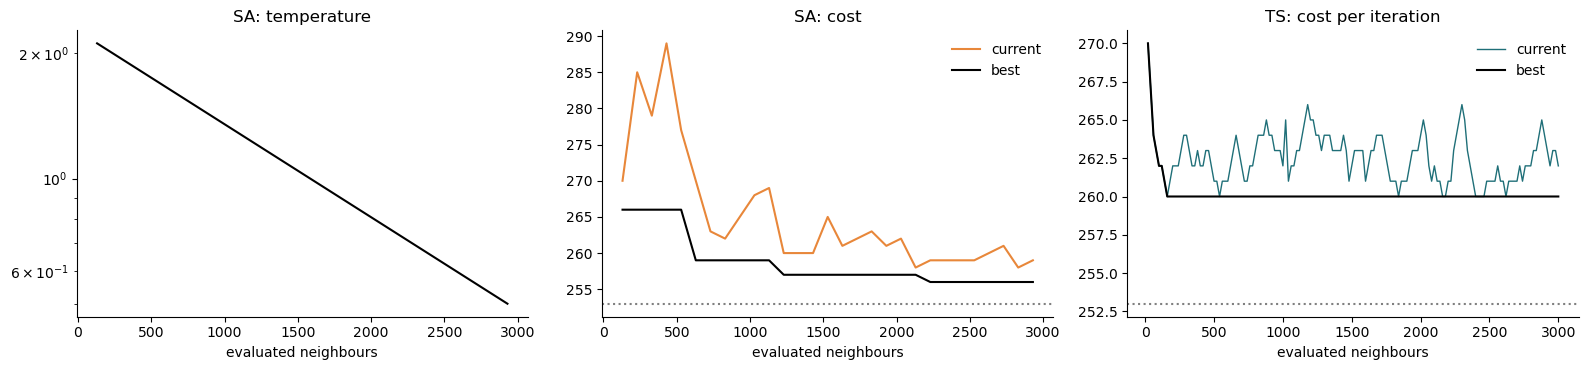

In [15]:
inst = byname["scpa1"]
rng = random.Random(1); st = initial_solution(inst, rng); c0 = st["cost"]
sa_best, sa_info = simulated_annealing(inst, st, rng, budget=BUDGET, p0=0.05, alpha=0.95, epoch=100)
check_state(inst, sa_best, minimal=True)
rng = random.Random(1); st = initial_solution(inst, rng)
ts_best, ts_info = tabu_search(inst, st, rng, budget=BUDGET, tenure=3, k=20)
check_state(inst, ts_best, minimal=True)
print(f"scpa1: start {c0:.0f}   SA {sa_best['cost']:.0f}   TS {ts_best['cost']:.0f}   best known {BEST['scpa1']}")
print(f"SA: T0 = {sa_info['T0']:.2f}, final T = {sa_info['T_end']:.3f}, acceptance rate {sa_info['accept_rate']:.2f}")
print(f"TS: {ts_info['iters']} iterations, all-tabu fallbacks {ts_info['tabu_fallback']}, aspiration used {ts_info['aspired']} times")

fig, axs = plt.subplots(1, 3, figsize=(16, 3.8))
h = np.array(sa_info["history"])
axs[0].plot(h[:, 0], h[:, 1], color="black"); axs[0].set_yscale("log"); axs[0].set_title("SA: temperature"); axs[0].set_xlabel("evaluated neighbours")
axs[1].plot(h[:, 0], h[:, 2], color=COL["SA"], label="current"); axs[1].plot(h[:, 0], h[:, 3], color="black", label="best")
axs[1].axhline(BEST["scpa1"], color="grey", ls=":"); axs[1].set_title("SA: cost"); axs[1].set_xlabel("evaluated neighbours"); axs[1].legend(frameon=False)
t = np.array([(x[1], x[2], x[3]) for x in ts_info["history"]])
axs[2].plot(t[:, 0], t[:, 1], color=COL["TS"], label="current", lw=1); axs[2].plot(t[:, 0], t[:, 2], color="black", label="best")
axs[2].axhline(BEST["scpa1"], color="grey", ls=":"); axs[2].set_title("TS: cost per iteration"); axs[2].set_xlabel("evaluated neighbours"); axs[2].legend(frameon=False)
for ax in axs: ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

**The first iterations of TS** (instance `scp42`, tenure 3): the dropped and the added sets, the cost after the move and whether a tabu move was accepted by aspiration.
Note that the current cost may *increase* - this is how TS leaves a local optimum - while the best cost never gets worse.

In [16]:
inst = byname["scp42"]; rng = random.Random(2); st = initial_solution(inst, rng)
_, info = tabu_search(inst, st, rng, budget=400, tenure=3, k=10)
pd.DataFrame([{"iteration": h[0], "evaluations": h[1], "current cost": h[2], "best cost": h[3], "dropped": list(h[4]), "added": list(h[5]), "tabu (aspiration)": h[6]}
              for h in info["history"][:12]]).set_index("iteration")

,evaluations,current cost,best cost,dropped,added,tabu (aspiration)
iteration,,,,,,
1,10,539.0,535.0,[86],[121],False
2,20,540.0,535.0,"[26, 66]",[93],False
3,30,543.0,535.0,"[21, 113]",[171],False
4,40,541.0,535.0,"[11, 239]","[111, 112]",False
5,50,544.0,535.0,[76],[103],False
6,60,540.0,535.0,[121],[86],False
7,70,537.0,535.0,[171],"[21, 113]",False
8,80,535.0,535.0,"[12, 49]",[51],False
9,90,531.0,531.0,"[43, 50]","[6, 44]",False


## 9. Experimental design

**Algorithm runs.** Every run starts from CH3 + RE built with the run's seed, uses a **budget of 3000 evaluated neighbours** (about 0.3 s) and returns the best cover found.
`run_task` is the single entry point used by all experiments; the tasks of a study are processed in **parallel** (forked worker processes, the seed alone determines a run, so the result does not depend on the scheduling).
CPU time is the process time of the run (the bookkeeping `check_state` is not timed). *Timings of the parameter studies are measured with several runs in parallel; the final comparison in Section 14 is run sequentially.*

**Instances.** The **tuning set** has 14 instances, two or one of every instance set (4, 5, 6, A, B, C, D); the other 28 instances are **held out**. The final comparison uses all 42 instances.
**Seeds.** Tuning runs use the seeds 101-105, the final comparison the seeds 1-10 (so tuning and final runs are independent).

| Study | Factors and levels | Design | Runs |
|---|---|---|---|
| **A: SA parameters** (Section 10) | $p_0\in\{0.005,0.01,0.02,0.05,0.1,0.3\}$, $\alpha\in\{0.9,0.95,0.98\}$, $L\in\{25,50,100,200\}$ | full factorial, 72 configurations | 72 x 14 x 3 |
| **B: TS parameters** (Section 11) | tenure $\in\{1,2,3,5,10,20\}$, sub-neighbourhood $k\in\{5,10,20,50,\text{all}\}$ | full factorial, 30 configurations | 30 x 14 x 3 |
| **C: building blocks** (Section 12) | RE after every move or only at the end (also at an **equal CPU time**); repair randomisation `rcl`; initial solution; TS only: aspiration, tabu attribute, dynamic tenure, long-term memory $\lambda$ | one factor at a time around the best configuration of A / B | ~ 17 x 14 x 5 |
| **F: confirmation** (Section 12.3) | the building-block changes that looked promising, tested on the **28 held-out instances** with new seeds (201-205) | paired tests with Holm correction; only confirmed changes enter the final configurations | 6 x 28 x 5 |
| **D: budget** (Section 13) | 1000, 3000, 10000, 30000 evaluations | final SA (fixed and budget-scaled cooling) and TS | 12 x 14 x 3 |
| **E: final comparison** (Section 14) | final SA, final TS, FI, BI | all 42 instances, 10 seeds, sequential timing | 4 x 42 x 10 |

**Responses.** Effectiveness: deviation from the best known solution (`dev`, %). Efficiency: CPU time and the budget; the anytime behaviour (`dev_at_c`: best-so-far after $c$ evaluations).

In [17]:
TUNE = ["scp42", "scp49", "scp51", "scp58", "scp62", "scp64", "scpa1", "scpa4", "scpb2", "scpb5", "scpc1", "scpc4", "scpd2", "scpd5"]
HELDOUT = [i["name"] for i in instances if i["name"] not in TUNE]
SEEDS_TUNE = (101, 102, 103, 104, 105)
SEEDS_FINAL = tuple(range(1, 11))
CHECKPOINTS = (100, 300, 1000, 3000)
print(len(TUNE), "tuning instances;", len(HELDOUT), "held-out instances")


def cost_at(trace, c):
    # best-so-far cost after c evaluations (the trace lists (evaluations, best cost) after each improvement)
    val = trace[0][1]
    for ev, cost in trace:
        if ev <= c:
            val = cost
        else:
            break
    return val


def run_task(task):
    # one run of one algorithm on one instance; the task is a plain tuple so that it can be sent to a worker process
    alg, name, seed, params, keep_trace = task
    inst = byname[name]
    rng = random.Random(seed)
    params = dict(params)
    t0 = time.process_time()
    st = initial_solution(inst, rng, params.pop("init", "CH3+RE"))
    cpu_init = time.process_time() - t0
    init_cost = st["cost"]
    t1 = time.process_time()
    if alg == "SA":
        best, info = simulated_annealing(inst, st, rng, **params)
    elif alg == "TS":
        best, info = tabu_search(inst, st, rng, **params)
    else:                                                       # "FI" / "BI"
        best, info = local_search(inst, st, rng, "first" if alg == "FI" else "best")
    cpu = time.process_time() - t1
    check_state(inst, best, minimal=True)                       # not timed
    row = {"algorithm": alg, "instance": name, "seed": seed, **task[3],
           "init_cost": init_cost, "final_cost": best["cost"], "best_known": BEST[name],
           "dev_init": dev(init_cost, BEST[name]), "dev": dev(best["cost"], BEST[name]),
           "evals": info["evals"], "cpu_s": cpu, "cpu_init_s": cpu_init}
    for c in CHECKPOINTS:
        row[f"dev_at_{c}"] = dev(cost_at(info["trace"], c) if c < info["evals"] else best["cost"], BEST[name])
    for key in ("iters", "tabu_fallback", "aspired", "accept_rate", "T0", "T_end", "moves"):
        if key in info:
            row[key] = info[key]
    if keep_trace:
        row["trace"] = info["trace"]
    return row


def run_many(tasks, procs=N_WORKERS):
    # tasks are processed in parallel in forked worker processes (results are returned in the order of the tasks)
    t0 = time.perf_counter()
    if procs > 1:
        with mp.get_context("fork").Pool(procs) as pool:
            rows = pool.map(run_task, tasks, chunksize=4)
    else:
        rows = [run_task(t) for t in tasks]
    print(f"{len(tasks)} runs in {time.perf_counter() - t0:.0f} s")
    return pd.DataFrame(rows)


def make_tasks(alg, grid, instance_names, seeds, base=None, keep_trace=False):
    return [(alg, nm, s, {**(base or {}), **g}, keep_trace) for g in grid for nm in instance_names for s in seeds]

14 tuning instances; 28 held-out instances


### Statistical tools
* `factor_table` - for one factor (or one configuration label): mean deviation over the instances, mean rank (Friedman), CPU time, difference to a reference level, and the
  **Wilcoxon signed-rank test** against the reference with **Holm-adjusted** p-values. The unit of analysis is the **instance**: for every instance the deviation is averaged over the seeds (paired by instance).
* `anova_table` - ANOVA of the run-level deviation with the instance as a blocking factor, the main effects and two-factor interactions; effect size = **partial $\eta^2$** = $SS_{effect}/(SS_{effect}+SS_{error})$.

In [18]:
def instance_means(df, factor, value="dev"):
    return df.pivot_table(index="instance", columns=factor, values=value, aggfunc="mean")


def factor_table(df, factor, ref, value="dev"):
    # factor: column name of the factor (or of a configuration label); ref: the reference level
    M = instance_means(df, factor, value)
    levels = list(M.columns)
    ranks = M.rank(axis=1).mean()
    cpu = df.groupby(factor).cpu_s.mean()
    rows, pvals = [], []
    for lv in levels:
        if lv == ref:
            p = np.nan
        elif np.allclose(M[lv], M[ref]):
            p = 1.0
        else:
            p = stats.wilcoxon(M[lv], M[ref]).pvalue
        pvals.append(p)
    mask = ~np.isnan(pvals)
    holm = np.full(len(levels), np.nan)
    if mask.any():
        holm[mask] = multipletests(np.array(pvals)[mask], method="holm")[1]
    for lv, p, ph in zip(levels, pvals, holm):
        rows.append({factor: lv, "mean dev %": M[lv].mean(), "mean rank": ranks[lv], "cpu s / run": cpu[lv],
                     "diff to ref [pp]": M[lv].mean() - M[ref].mean(), "Wilcoxon p": p, "Holm p": ph})
    fried = stats.friedmanchisquare(*[M[lv] for lv in levels]).pvalue if len(levels) > 2 else np.nan
    return pd.DataFrame(rows).set_index(factor), fried


def anova_table(df, factors, interactions=True):
    d = df.rename(columns={f: f"f_{f}" for f in factors}).copy()
    for f in factors:
        d[f"f_{f}"] = d[f"f_{f}"].astype(str)
    terms = [f"C(f_{f})" for f in factors]
    if interactions:
        terms += [f"C(f_{a}):C(f_{b})" for a, b in itertools.combinations(factors, 2)]
    model = smf.ols("dev ~ C(instance) + " + " + ".join(terms), data=d).fit()
    tab = sm.stats.anova_lm(model, typ=2)
    ss_err = tab.loc["Residual", "sum_sq"]
    tab["partial eta2"] = tab["sum_sq"] / (tab["sum_sq"] + ss_err)
    tab.index = [i.replace("C(instance)", "instance").replace("C(f_", "").replace(")", "").replace(":", " x ") for i in tab.index]
    return tab.drop(index="Residual")[["df", "F", "PR(>F)", "partial eta2"]].rename(columns={"PR(>F)": "p"})

## 10. Experiment A - simulated annealing parameters

Full factorial design: initial acceptance probability $p_0$ (**how hot** the start is), cooling ratio $\alpha$ and epoch length $L$ (**how fast** it cools): 72 configurations.
All other building blocks are at their defaults (RE after every move, greedy repair, start CH3 + RE).

In [19]:
SA_GRID = [dict(budget=BUDGET, p0=p0, alpha=a, epoch=L) for p0 in (0.005, 0.01, 0.02, 0.05, 0.1, 0.3) for a in (0.9, 0.95, 0.98) for L in (25, 50, 100, 200)]
resA = run_many(make_tasks("SA", SA_GRID, TUNE, SEEDS_TUNE[:3]))
resA["cooling"] = resA.alpha ** (resA.budget / resA.epoch)           # total temperature reduction  T_end / T0  (ignoring the calibration sample)
gA = resA.groupby(["p0", "alpha", "epoch"])
tabA = gA.agg(dev=("dev", "mean"), cpu=("cpu_s", "mean"), accept=("accept_rate", "mean"), cooling=("cooling", "first")).reset_index()
print("best 8 configurations:"); tabA.sort_values("dev").head(8).round(3)

3024 runs in 141 s


best 8 configurations:


,p0,alpha,epoch,dev,cpu,accept,cooling
19,0.010,0.95,200,1.267,0.312,0.123,0.463
33,0.020,0.98,50,1.292,0.266,0.119,0.298
42,0.050,0.95,100,1.322,0.270,0.144,0.215
10,0.005,0.98,100,1.323,0.303,0.113,0.545
22,0.010,0.98,100,1.333,0.306,0.130,0.545
15,0.010,0.90,200,1.333,0.295,0.091,0.206
35,0.020,0.98,200,1.338,0.284,0.187,0.739
46,0.050,0.98,100,1.364,0.282,0.216,0.545


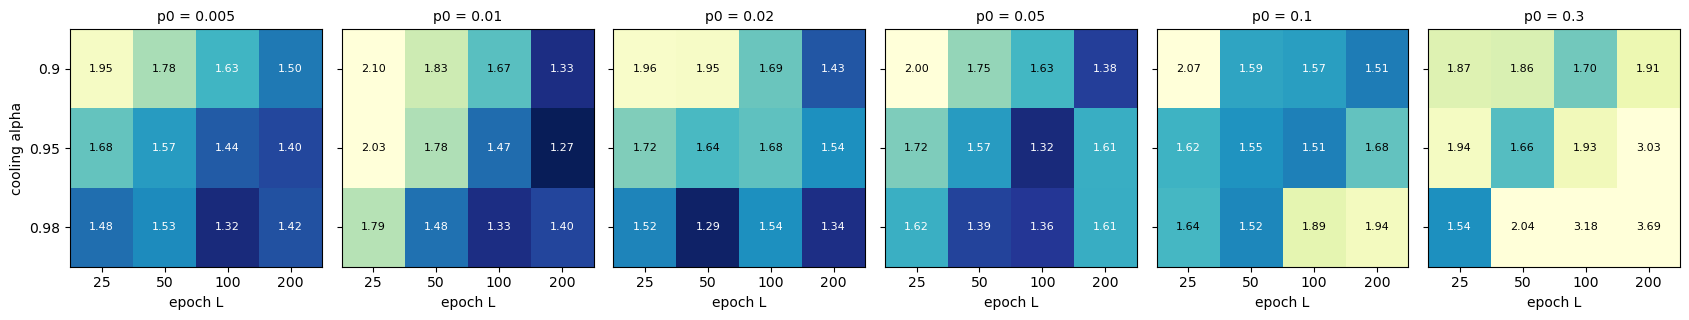

In [20]:
# heat maps: average deviation [%] for p0 (panels) x alpha (rows) x epoch length (columns)
fig, axs = plt.subplots(1, 6, figsize=(17, 3.3), sharey=True)
vmax = np.percentile(tabA.dev, 90)
for ax, p0 in zip(axs, sorted(tabA.p0.unique())):
    piv = tabA[tabA.p0 == p0].pivot(index="alpha", columns="epoch", values="dev")
    im = ax.imshow(piv.values, cmap="YlGnBu_r", vmin=tabA.dev.min(), vmax=vmax, aspect="auto")
    ax.set_xticks(range(piv.shape[1])); ax.set_xticklabels(piv.columns); ax.set_yticks(range(piv.shape[0])); ax.set_yticklabels(piv.index)
    for (i, j), v in np.ndenumerate(piv.values):
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if v < (tabA.dev.min() + vmax) / 2 else "black")
    ax.set_title(f"p0 = {p0}", fontsize=10); ax.set_xlabel("epoch L")
axs[0].set_ylabel("cooling alpha")
plt.tight_layout(); plt.show()

**Main effects** (each level averaged over the other factors) and **ANOVA** with the instance as block:

In [21]:
main_effects = pd.concat({f: resA.groupby(f).agg(dev=("dev", "mean"), cpu=("cpu_s", "mean"), accept=("accept_rate", "mean")) for f in ["p0", "alpha", "epoch"]}, names=["factor", "level"])
display(main_effects.round(3))
anovaA = anova_table(resA, ["p0", "alpha", "epoch"])
display(anovaA.round(4))

dev    cpu  accept
factor level                        
p0     0.005    1.558  0.307   0.077
       0.010    1.624  0.301   0.087
       0.020    1.608  0.283   0.103
       0.050    1.581  0.291   0.134
       0.100    1.673  0.274   0.174
       0.300    2.195  0.271   0.306
alpha  0.900    1.735  0.296   0.100
       0.950    1.682  0.285   0.141
       0.980    1.703  0.283   0.200
epoch  25.000   1.791  0.294   0.084
       50.000   1.654  0.290   0.120
       100.000  1.660  0.286   0.167
       200.000  1.721  0.281   0.216

,df,F,p,partial eta2
instance,13.0,221.4731,0.0000,0.4923
p0,5.0,30.5198,0.0000,0.0489
alpha,2.0,0.7419,0.4763,0.0005
epoch,3.0,3.1969,0.0225,0.0032
p0 x alpha,10.0,7.9193,0.0000,0.0260
p0 x epoch,15.0,9.4637,0.0000,0.0456
alpha x epoch,6.0,8.7928,0.0000,0.0175


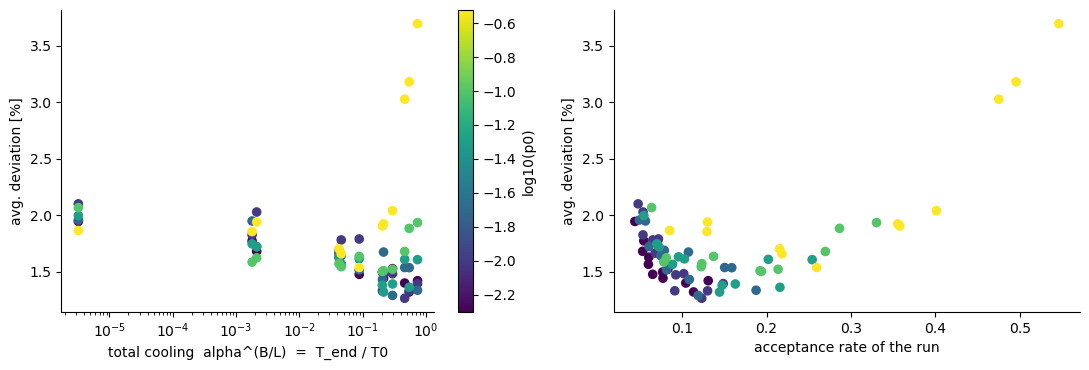

In [22]:
# the cooling that is really achieved matters: T_end/T0 = alpha^(B/L) against the deviation
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
sc = axs[0].scatter(tabA.cooling, tabA.dev, c=np.log10(tabA.p0), cmap="viridis", s=35)
axs[0].set_xscale("log"); axs[0].set_xlabel("total cooling  alpha^(B/L)  =  T_end / T0"); axs[0].set_ylabel("avg. deviation [%]")
plt.colorbar(sc, ax=axs[0], label="log10(p0)")
sc = axs[1].scatter(tabA.accept, tabA.dev, c=np.log10(tabA.p0), cmap="viridis", s=35)
axs[1].set_xlabel("acceptance rate of the run"); axs[1].set_ylabel("avg. deviation [%]")
for ax in axs: ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

In [23]:
# best SA configuration (lowest average deviation on the tuning instances) and its comparison with the other leading configurations
bestA = tabA.sort_values("dev").iloc[0]
SA_BEST = dict(budget=BUDGET, p0=float(bestA.p0), alpha=float(bestA.alpha), epoch=int(bestA.epoch))
print("best SA configuration:", SA_BEST, f"-> {bestA.dev:.3f} %")
resA["config"] = resA.p0.astype(str) + " / " + resA.alpha.astype(str) + " / " + resA.epoch.astype(str)
ref = f"{SA_BEST['p0']} / {SA_BEST['alpha']} / {SA_BEST['epoch']}"
lab = lambda r: f"{r.p0} / {r.alpha} / {int(r.epoch)}"
top = list(tabA.sort_values("dev").head(6).apply(lab, axis=1)) + [lab(tabA.sort_values("dev").iloc[-1])]      # the 6 best and the worst one
tabtop, fr = factor_table(resA[resA.config.isin(top)], "config", ref)
print(f"Friedman test over these 7 configurations (instances as blocks): p = {fr:.4g}   [config = p0 / alpha / epoch]"); tabtop.round(4)

best SA configuration: {'budget': 3000, 'p0': 0.01, 'alpha': 0.95, 'epoch': 200} -> 1.267 %
Friedman test over these 7 configurations (instances as blocks): p = 3.177e-07   [config = p0 / alpha / epoch]


,mean dev %,mean rank,cpu s / run,diff to ref [pp],Wilcoxon p,Holm p
config,,,,,,
0.005 / 0.98 / 100,1.3232,3.2500,0.3025,0.0557,0.8658,1.0000
0.01 / 0.9 / 200,1.3334,3.7500,0.2952,0.0659,0.2489,1.0000
0.01 / 0.95 / 200,1.2675,3.1429,0.3123,0.0000,NaN,NaN
0.01 / 0.98 / 100,1.3332,3.6071,0.3065,0.0657,0.3452,1.0000
0.02 / 0.98 / 50,1.2924,3.7500,0.2657,0.0250,0.7532,1.0000
0.05 / 0.95 / 100,1.3222,3.7143,0.2703,0.0547,0.7353,1.0000
0.3 / 0.98 / 200,3.6940,6.7857,0.2354,2.4266,0.0015,0.0088


## 11. Experiment B - tabu search parameters

Full factorial design of the **tenure** (iterations a modification stays tabu) and the **sub-neighbourhood size** `k` (neighbours evaluated per iteration; "all" = the complete neighbourhood, $k\ge|S|$).
With a fixed budget the two parameters also decide *how many iterations* TS can perform: iterations $\approx B/k$.

In [24]:
ALL = 999                                                  # k = ALL evaluates the whole neighbourhood
TS_GRID = [dict(budget=BUDGET, tenure=t, k=k) for t in (1, 2, 3, 5, 10, 20) for k in (5, 10, 20, 50, ALL)]
resB = run_many(make_tasks("TS", TS_GRID, TUNE, SEEDS_TUNE[:3]))
resB["fallback_share"] = resB.tabu_fallback / resB.iters
tabB = resB.groupby(["tenure", "k"]).agg(dev=("dev", "mean"), cpu=("cpu_s", "mean"), iters=("iters", "mean"), fallback=("fallback_share", "mean"), aspired=("aspired", "mean")).reset_index()
print("best 8 configurations:"); tabB.sort_values("dev").head(8).round(3)

1260 runs in 52 s
best 8 configurations:


,tenure,k,dev,cpu,iters,fallback,aspired
12,3,20,0.991,0.267,150.000,0.0,0.500
7,2,20,1.093,0.274,150.000,0.0,0.405
6,2,10,1.137,0.281,300.000,0.0,0.357
17,5,20,1.190,0.310,150.000,0.0,0.619
18,5,50,1.250,0.297,66.405,0.0,0.524
19,5,999,1.309,0.270,57.000,0.0,0.476
2,1,20,1.312,0.296,150.000,0.0,0.143
1,1,10,1.322,0.301,300.000,0.0,0.190


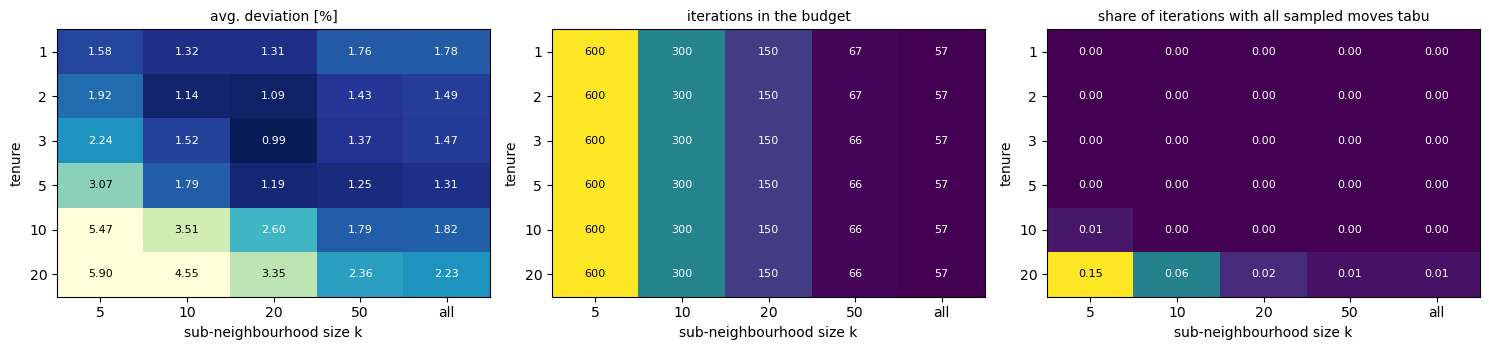

In [25]:
fig, axs = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, (col, title, fmt) in zip(axs, [("dev", "avg. deviation [%]", "{:.2f}"), ("iters", "iterations in the budget", "{:.0f}"), ("fallback", "share of iterations with all sampled moves tabu", "{:.2f}")]):
    piv = tabB.pivot(index="tenure", columns="k", values=col)
    im = ax.imshow(piv.values, cmap="YlGnBu_r" if col == "dev" else "viridis", aspect="auto", vmax=np.percentile(piv.values, 92) if col == "dev" else None)
    ax.set_xticks(range(piv.shape[1])); ax.set_xticklabels(["all" if c == ALL else c for c in piv.columns]); ax.set_yticks(range(piv.shape[0])); ax.set_yticklabels(piv.index)
    for (i, j), v in np.ndenumerate(piv.values):
        ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=8, color="white" if im.norm(v) < 0.5 else "black")
    ax.set_title(title, fontsize=10); ax.set_xlabel("sub-neighbourhood size k"); ax.set_ylabel("tenure")
plt.tight_layout(); plt.show()

In [26]:
main_effectsB = pd.concat({f: resB.groupby(f).agg(dev=("dev", "mean"), cpu=("cpu_s", "mean"), iters=("iters", "mean")) for f in ["tenure", "k"]}, names=["factor", "level"])
display(main_effectsB.round(3))
anovaB = anova_table(resB, ["tenure", "k"])
display(anovaB.round(4))
bestB = tabB.sort_values("dev").iloc[0]
TS_BEST = dict(budget=BUDGET, tenure=int(bestB.tenure), k=int(bestB.k))
print("best TS configuration:", TS_BEST, f"-> {bestB.dev:.3f} %")
resB["config"] = "tenure " + resB.tenure.astype(str) + " / k " + resB.k.astype(str)
refB = f"tenure {TS_BEST['tenure']} / k {TS_BEST['k']}"
labB = lambda r: f"tenure {int(r.tenure)} / k {int(r.k)}"
topB = list(tabB.sort_values("dev").head(6).apply(labB, axis=1)) + [labB(tabB.sort_values("dev").iloc[-1])]    # the 6 best and the worst one
tabtopB, frB = factor_table(resB[resB.config.isin(topB)], "config", refB)
print(f"Friedman test over these 7 configurations: p = {frB:.4g}"); tabtopB.round(4)

dev    cpu    iters
factor level                       
tenure 1      1.552  0.291  234.805
       2      1.414  0.288  234.729
       3      1.519  0.275  234.690
       5      1.722  0.294  234.681
       10     3.040  0.281  234.619
       20     3.681  0.275  234.457
k      5      3.364  0.301  600.000
       10     2.306  0.284  300.000
       20     1.757  0.278  150.000
       50     1.663  0.279   66.341
       999    1.683  0.277   56.976

,df,F,p,partial eta2
instance,13.0,22.1075,0.0,0.1910
tenure,5.0,121.6931,0.0,0.3333
k,4.0,83.3619,0.0,0.2151
tenure x k,20.0,13.6142,0.0,0.1828


best TS configuration: {'budget': 3000, 'tenure': 3, 'k': 20} -> 0.991 %


Friedman test over these 7 configurations: p = 1.391e-07


,mean dev %,mean rank,cpu s / run,diff to ref [pp],Wilcoxon p,Holm p
config,,,,,,
tenure 2 / k 10,1.1368,3.5357,0.2814,0.1461,0.3329,0.6227
tenure 2 / k 20,1.0926,3.2500,0.2745,0.1018,0.2076,0.6227
tenure 20 / k 5,5.8982,7.0000,0.3050,4.9075,0.0001,0.0007
tenure 3 / k 20,0.9907,2.5357,0.2667,0.0000,NaN,NaN
tenure 5 / k 20,1.1902,4.1071,0.3105,0.1994,0.3078,0.6227
tenure 5 / k 50,1.2500,3.6786,0.2969,0.2593,0.0284,0.1253
tenure 5 / k 999,1.3089,3.8929,0.2697,0.3181,0.0251,0.1253


## 12. Experiment C - building blocks

One factor at a time around the **best configuration** of Experiments A and B (5 seeds on the 14 tuning instances). Every block is compared with the reference configuration (marked `ref`):

* **RE after every move** (`re_step`): the neighbour is always a minimal cover (reference) vs. **no RE during the search** (RE only at the end on the best solution) - the plan item "perform RE, try also on every step".
  Without RE a move is cheaper but the evaluated costs are inflated by redundant sets.
* **Repair randomisation** `rcl` (GRASP idea): 1 (greedy), 2, 3.
* **Initial solution:** CH3 + RE (reference), CH3 without RE, random CH1 + RE.
* **TS only:** aspiration criterion on/off; tabu attribute (`both` = removed sets may not return and added sets may not be removed, `add_only`, `drop_only`);
  dynamic vs. fixed tenure; long-term memory (frequency penalty $\lambda$).

In [27]:
def levels_of(base, name, values):
    return [{**base, name: v} for v in values]

SA_BLOCKS = {
    "re_step": levels_of(SA_BEST, "re_step", [True, False]),
    "rcl":     levels_of(SA_BEST, "rcl", [1, 2, 3]),
    "init":    levels_of(SA_BEST, "init", ["CH3+RE", "CH3", "CH1+RE"]),
}
TS_BLOCKS = {
    "re_step":    levels_of(TS_BEST, "re_step", [True, False]),
    "rcl":        levels_of(TS_BEST, "rcl", [1, 2, 3]),
    "init":       levels_of(TS_BEST, "init", ["CH3+RE", "CH3", "CH1+RE"]),
    "aspiration": levels_of(TS_BEST, "aspiration", [True, False]),
    "attr":       levels_of(TS_BEST, "attr", ["both", "add_only", "drop_only"]),
    "dynamic":    levels_of(TS_BEST, "dynamic", [True, False]),
    "lam":        levels_of(TS_BEST, "lam", [0.0, 0.5, 2.0]),
}
REF_LEVEL = {"re_step": True, "rcl": 1, "init": "CH3+RE", "aspiration": True, "attr": "both", "dynamic": True, "lam": 0.0}

blocks = []
for alg, B in (("SA", SA_BLOCKS), ("TS", TS_BLOCKS)):
    for name, grid in B.items():
        df = run_many(make_tasks(alg, grid, TUNE, SEEDS_TUNE))
        df["block"] = name
        df["level"] = df[name]
        blocks.append(df)
resC = pd.concat(blocks, ignore_index=True)

140 runs in 4 s


210 runs in 9 s


210 runs in 8 s


140 runs in 5 s


210 runs in 13 s


210 runs in 9 s


140 runs in 6 s


210 runs in 8 s


140 runs in 7 s


210 runs in 8 s


In [28]:
rowsC = []
for alg in ("SA", "TS"):
    for name in (SA_BLOCKS if alg == "SA" else TS_BLOCKS):
        d = resC[(resC.algorithm == alg) & (resC.block == name)].copy()
        d["level"] = d["level"].astype(str)
        t, fr = factor_table(d, "level", str(REF_LEVEL[name]))
        t = t.reset_index(); t.insert(0, "block", name); t.insert(0, "algorithm", alg); t["Friedman p"] = fr
        rowsC.append(t)
tabC = pd.concat(rowsC, ignore_index=True)
tabC.round(4)

,algorithm,block,level,mean dev %,mean rank,cpu s / run,diff to ref [pp],Wilcoxon p,Holm p,Friedman p
0,SA,re_step,False,2.8051,1.9643,0.1600,1.4839,0.0015,0.0015,NaN
1,SA,re_step,True,1.3213,1.0357,0.2735,0.0000,NaN,NaN,NaN
2,SA,rcl,1,1.3213,2.2500,0.2633,0.0000,NaN,NaN,0.0749
3,SA,rcl,2,0.8515,1.5357,0.2873,-0.4698,0.0597,0.1195,0.0749
4,SA,rcl,3,1.1283,2.2143,0.2984,-0.1930,0.4631,0.4631,0.0749
5,SA,init,CH1+RE,1.8375,2.3571,0.2662,0.5163,0.0382,0.0763,0.1418
6,SA,init,CH3,1.4021,1.9286,0.2603,0.0808,0.5337,0.5337,0.1418
7,SA,init,CH3+RE,1.3213,1.7143,0.2789,0.0000,NaN,NaN,0.1418
8,TS,re_step,False,2.6789,1.9286,0.1707,1.5889,0.0022,0.0022,NaN
9,TS,re_step,True,1.0901,1.0714,0.2805,0.0000,NaN,NaN,NaN


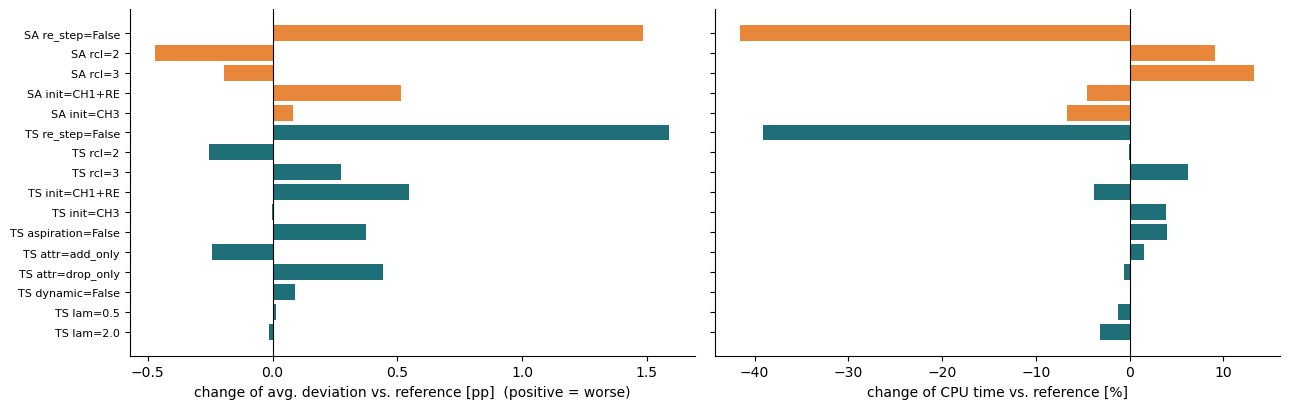

In [29]:
# visual summary: change of the deviation and of the CPU time relative to the reference level (positive = worse / slower)
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
labels, d1, d2, cols = [], [], [], []
for alg in ("SA", "TS"):
    for name in (SA_BLOCKS if alg == "SA" else TS_BLOCKS):
        s = tabC[(tabC.algorithm == alg) & (tabC.block == name)]
        r = s[s.level == str(REF_LEVEL[name])].iloc[0]
        for _, x in s.iterrows():
            if x.level == str(REF_LEVEL[name]): continue
            labels.append(f"{alg} {name}={x.level}"); d1.append(x["diff to ref [pp]"]); d2.append(100 * (x["cpu s / run"] / r["cpu s / run"] - 1)); cols.append(COL[alg])
y = np.arange(len(labels))
axs[0].barh(y, d1, color=cols); axs[0].set_yticks(y); axs[0].set_yticklabels(labels, fontsize=8); axs[0].axvline(0, color="black", lw=0.8)
axs[0].set_xlabel("change of avg. deviation vs. reference [pp]  (positive = worse)"); axs[0].invert_yaxis()
axs[1].barh(y, d2, color=cols); axs[1].set_yticks(y); axs[1].set_yticklabels([]); axs[1].axvline(0, color="black", lw=0.8)
axs[1].set_xlabel("change of CPU time vs. reference [%]"); axs[1].invert_yaxis()
for ax in axs: ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

### 12.1 Is "RE after every move" worth its cost? (equal CPU time)
Skipping RE during the search makes one evaluation about **40 % cheaper** (see the CPU column above), but the deviation at the **same budget** is much worse.
The fair question for efficiency is therefore: what if the search *without* RE is simply allowed to run **as long (CPU time)** as the search with RE?
The budget of the "no RE" variant is scaled by the ratio of the measured CPU times.

In [30]:
c2 = []
for alg, cfg in (("SA", SA_BEST), ("TS", TS_BEST)):
    on = resC[(resC.algorithm == alg) & (resC.block == "re_step") & (resC.re_step == True)]
    off = resC[(resC.algorithm == alg) & (resC.block == "re_step") & (resC.re_step == False)]
    scale = on.cpu_s.mean() / off.cpu_s.mean()
    b2 = int(round(BUDGET * scale / 100.0) * 100)
    d = run_many(make_tasks(alg, [{**cfg, "re_step": False, "budget": b2}], TUNE, SEEDS_TUNE))
    d["variant"] = f"no RE, equal CPU (B={b2})"
    c2 += [on.assign(variant=f"RE every move (B={BUDGET})"), off.assign(variant=f"no RE (B={BUDGET})"), d]
resC2 = pd.concat(c2, ignore_index=True)
rows = []
for alg in ("SA", "TS"):
    d = resC2[resC2.algorithm == alg]
    t, fr = factor_table(d, "variant", f"RE every move (B={BUDGET})")
    t = t.reset_index(); t.insert(0, "algorithm", alg); rows.append(t)
pd.concat(rows, ignore_index=True).round(4)

70 runs in 3 s


70 runs in 3 s


,algorithm,variant,mean dev %,mean rank,cpu s / run,diff to ref [pp],Wilcoxon p,Holm p
0,SA,RE every move (B=3000),1.3213,1.1071,0.2735,0.0000,NaN,NaN
1,SA,no RE (B=3000),2.8051,2.7500,0.1600,1.4839,0.0015,0.0029
2,SA,"no RE, equal CPU (B=5100)",2.6478,2.1429,0.2807,1.3265,0.0022,0.0029
3,TS,RE every move (B=3000),1.0901,1.1786,0.2805,0.0000,NaN,NaN
4,TS,no RE (B=3000),2.6789,2.7143,0.1707,1.5889,0.0022,0.0044
5,TS,"no RE, equal CPU (B=4900)",2.4794,2.1071,0.2649,1.3894,0.0033,0.0044


### 12.2 Candidates for the final configurations
In the one-factor-at-a-time study some changes looked promising (a tabu attribute that only forbids re-adding removed sets, `attr = add_only`; a slightly randomised repair, `rcl = 2`),
but with 14 instances and Holm correction most of them are not significant. Choosing the winner of many comparisons on the same data over-states its effect (the *winner's curse*),
so we **confirm the candidates on the 28 held-out instances with new seeds** and adopt a change only if it is better with a Holm-adjusted $p<0.05$.

In [31]:
SEEDS_CONF = (201, 202, 203, 204, 205)
CAND = {"SA": {"reference": SA_BEST, "rcl=2": {**SA_BEST, "rcl": 2}},
        "TS": {"reference": TS_BEST, "attr=add_only": {**TS_BEST, "attr": "add_only"}, "rcl=2": {**TS_BEST, "rcl": 2},
               "attr=add_only + rcl=2": {**TS_BEST, "attr": "add_only", "rcl": 2}}}
conf = []
for alg, cs in CAND.items():
    for label, cfg in cs.items():
        d = run_many(make_tasks(alg, [cfg], HELDOUT, SEEDS_CONF)); d["candidate"] = label; conf.append(d)
resF = pd.concat(conf, ignore_index=True)

FINAL, rows = {}, []
for alg in ("SA", "TS"):
    t, fr = factor_table(resF[resF.algorithm == alg], "candidate", "reference")
    ok = t[(t["Holm p"] < 0.05) & (t["diff to ref [pp]"] < 0)]
    chosen = ok["mean dev %"].idxmin() if len(ok) else "reference"
    FINAL[alg] = CAND[alg][chosen]
    t = t.reset_index(); t.insert(0, "algorithm", alg); t["adopted"] = t.candidate == chosen; rows.append(t)
SA_FINAL, TS_FINAL = FINAL["SA"], FINAL["TS"]
print("final SA configuration:", SA_FINAL); print("final TS configuration:", TS_FINAL)
tabF = pd.concat(rows, ignore_index=True); tabF.round(4)

140 runs in 5 s


140 runs in 6 s


140 runs in 6 s


140 runs in 6 s


140 runs in 6 s


140 runs in 6 s
final SA configuration: {'budget': 3000, 'p0': 0.01, 'alpha': 0.95, 'epoch': 200}
final TS configuration: {'budget': 3000, 'tenure': 3, 'k': 20}


,algorithm,candidate,mean dev %,mean rank,cpu s / run,diff to ref [pp],Wilcoxon p,Holm p,adopted
0,SA,rcl=2,1.0663,1.5179,0.2725,-0.2611,0.4140,0.4140,False
1,SA,reference,1.3274,1.4821,0.2431,0.0000,NaN,NaN,True
2,TS,attr=add_only,0.9787,2.1071,0.2581,-0.0690,0.1165,0.3496,False
3,TS,attr=add_only + rcl=2,0.8892,2.3036,0.2704,-0.1585,0.1229,0.3496,False
4,TS,rcl=2,1.0804,2.9821,0.2750,0.0327,0.4115,0.4115,False
5,TS,reference,1.0478,2.6071,0.2737,0.0000,NaN,NaN,True


## 13. Experiment D - computation budget (efficiency)

Does the quality improve with more evaluations, and what does it cost? The final SA and TS with budgets of 1000, 3000, 10000 and 30000 evaluated neighbours
For SA two variants: the schedule of the tuned configuration is kept (**"SA"**: a longer run simply continues to cool further) or **scaled with the budget** (**"SA scaled"**: the epoch length grows with the budget, so the total cooling $\alpha^{B/L}$ stays the same).
The TS parameters (tenure, $k$) are kept.

42 runs in 1 s


42 runs in 1 s


42 runs in 1 s


42 runs in 3 s


42 runs in 3 s


...

42 runs in 8 s


42 runs in 9 s


42 runs in 24 s


42 runs in 25 s


42 runs in 24 s


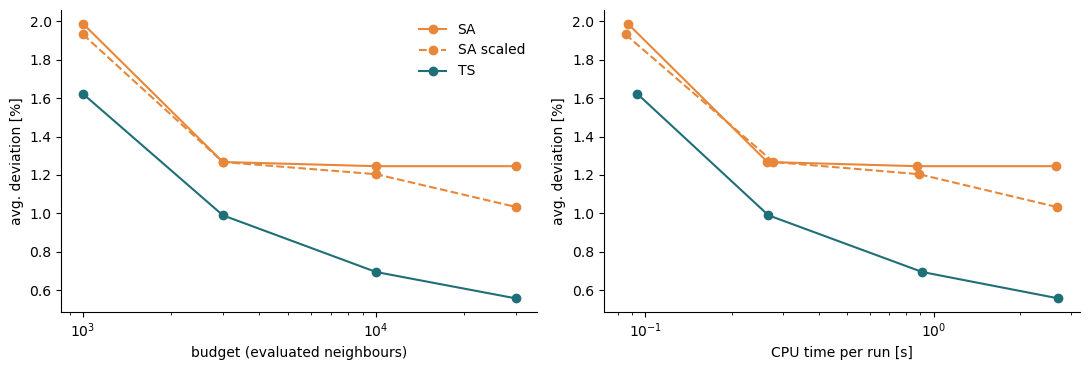

dev                     cpu                 
label      SA SA scaled     TS     SA SA scaled     TS
budget                                                
1000    1.986     1.930  1.621  0.087     0.085  0.094
3000    1.267     1.267  0.991  0.265     0.278  0.267
10000   1.246     1.204  0.696  0.875     0.890  0.913
30000   1.246     1.034  0.559  2.663     2.671  2.709

In [32]:
def budget_tasks(alg, cfg, b, scale_cooling=False):
    c = {**cfg, "budget": b}
    if scale_cooling:                                   # keep the total cooling alpha^(B/L) constant: epoch grows with the budget
        c["epoch"] = max(1, int(round(cfg["epoch"] * b / BUDGET)))
    return make_tasks(alg, [c], TUNE, SEEDS_TUNE[:3])

parts = []
for b in (1000, 3000, 10000, 30000):
    for label, alg, cfg, sc in (("SA", "SA", SA_FINAL, False), ("SA scaled", "SA", SA_FINAL, True), ("TS", "TS", TS_FINAL, False)):
        d = run_many(budget_tasks(alg, cfg, b, sc)); d["label"] = label; parts.append(d)
resD = pd.concat(parts, ignore_index=True)
tabD = resD.groupby(["label", "budget"]).agg(dev=("dev", "mean"), cpu=("cpu_s", "mean")).reset_index()
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
for lab, ls_ in (("SA", "-"), ("SA scaled", "--"), ("TS", "-")):
    s_ = tabD[tabD.label == lab]; c_ = COL["TS"] if lab == "TS" else COL["SA"]
    axs[0].plot(s_.budget, s_.dev, marker="o", color=c_, ls=ls_, label=lab); axs[1].plot(s_.cpu, s_.dev, marker="o", color=c_, ls=ls_, label=lab)
axs[0].set_xscale("log"); axs[0].set_xlabel("budget (evaluated neighbours)"); axs[0].set_ylabel("avg. deviation [%]"); axs[0].legend(frameon=False)
axs[1].set_xscale("log"); axs[1].set_xlabel("CPU time per run [s]"); axs[1].set_ylabel("avg. deviation [%]")
for ax in axs: ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()
tabD.pivot(index="budget", columns="label", values=["dev", "cpu"]).round(3)

## 14. Final comparison: TS vs. SA vs. local search

The final SA and TS (Section 12.2, budget 3000) and the FI / BI local search of Assignment 2 on **all 42 instances with 10 new seeds (1-10)**; the same seed means the **same CH3 + RE start** for all four algorithms.
Run **sequentially** (clean CPU times). The statistical analysis uses the **instance as the unit** (deviation averaged over the 10 seeds): Friedman test, pairwise Wilcoxon signed-rank tests with Holm correction.

In [33]:
final_tasks = [(alg, inst["name"], seed, ({} if alg in ("FI", "BI") else (SA_FINAL if alg == "SA" else TS_FINAL)), True)
               for inst in instances for seed in SEEDS_FINAL for alg in ("TS", "SA", "FI", "BI")]
resE = run_many(final_tasks, procs=1)
traces = {(r.algorithm, r.instance, r.seed): r.trace for r in resE.itertuples()}
resE = resE.drop(columns="trace")
resE["tuned"] = resE.instance.isin(TUNE)
print(f"start (CH3 + RE): avg. deviation {resE.dev_init.mean():.2f} %")

1680 runs in 213 s
start (CH3 + RE): avg. deviation 6.03 %


In [34]:
ALGS = ["TS", "SA", "FI", "BI"]
g = resE.groupby("algorithm")
inst_mean = resE.pivot_table(index="instance", columns="algorithm", values="dev", aggfunc="mean")[ALGS]
inst_best = resE.pivot_table(index="instance", columns="algorithm", values="dev", aggfunc="min")[ALGS]
summaryE = pd.DataFrame({
    "avg dev % (all 42)":   inst_mean.mean(),
    "avg dev % (28 held-out)": inst_mean.loc[HELDOUT].mean(),
    "std over seeds (avg of instances)": resE.groupby(["algorithm", "instance"]).dev.std().groupby("algorithm").mean(),
    "avg of best-of-10 dev %": inst_best.mean(),
    "instances with best known reached (any seed)": (inst_best < 1e-9).sum(),
    "evaluations / run": g.evals.mean(),
    "CPU s / run": g.cpu_s.mean(),
    "total CPU s (420 runs)": g.cpu_s.sum(),
}).loc[ALGS]
summaryE.round(3)

,avg dev % (all 42),avg dev % (28 held-out),std over seeds (avg of instances),avg of best-of-10 dev %,instances with best known reached (any seed),evaluations / run,CPU s / run,total CPU s (420 runs)
algorithm,,,,,,,,
TS,1.036,0.958,0.526,0.415,25,3000.000,0.228,95.898
SA,1.342,1.257,0.548,0.685,19,3000.000,0.222,93.448
FI,2.913,2.728,1.195,1.409,7,117.998,0.008,3.344
BI,2.675,2.543,1.154,1.228,8,246.310,0.016,6.919


In [35]:
# statistical tests on the per-instance mean deviations (42 blocks)
fr = stats.friedmanchisquare(*[inst_mean[a] for a in ALGS])
print(f"Friedman test over TS, SA, FI, BI: chi2 = {fr.statistic:.1f}, p = {fr.pvalue:.3g}")
ranks = inst_mean.rank(axis=1).mean()
pairs = list(itertools.combinations(ALGS, 2))
rows = []
for a, b in pairs:
    w = stats.wilcoxon(inst_mean[a], inst_mean[b])
    rows.append({"A": a, "B": b, "mean dev A": inst_mean[a].mean(), "mean dev B": inst_mean[b].mean(),
                 "A better on": int((inst_mean[a] < inst_mean[b]).sum()), "B better on": int((inst_mean[b] < inst_mean[a]).sum()), "p": w.pvalue})
pw = pd.DataFrame(rows)
pw["Holm p"] = multipletests(pw.p, method="holm")[1]
print("mean ranks:", ranks.round(2).to_dict())
pw.round(5)

Friedman test over TS, SA, FI, BI: chi2 = 90.1, p = 2.07e-19
mean ranks: {'TS': 1.35, 'SA': 1.89, 'FI': 3.68, 'BI': 3.08}


,A,B,mean dev A,mean dev B,A better on,B better on,p,Holm p
0,TS,SA,1.03638,1.34223,28,7,0.00001,0.00002
1,TS,FI,1.03638,2.91275,41,1,0.00000,0.00000
2,TS,BI,1.03638,2.67480,38,2,0.00000,0.00000
3,SA,FI,1.34223,2.91275,39,2,0.00000,0.00000
4,SA,BI,1.34223,2.67480,38,3,0.00000,0.00000
5,FI,BI,2.91275,2.67480,7,29,0.00017,0.00017


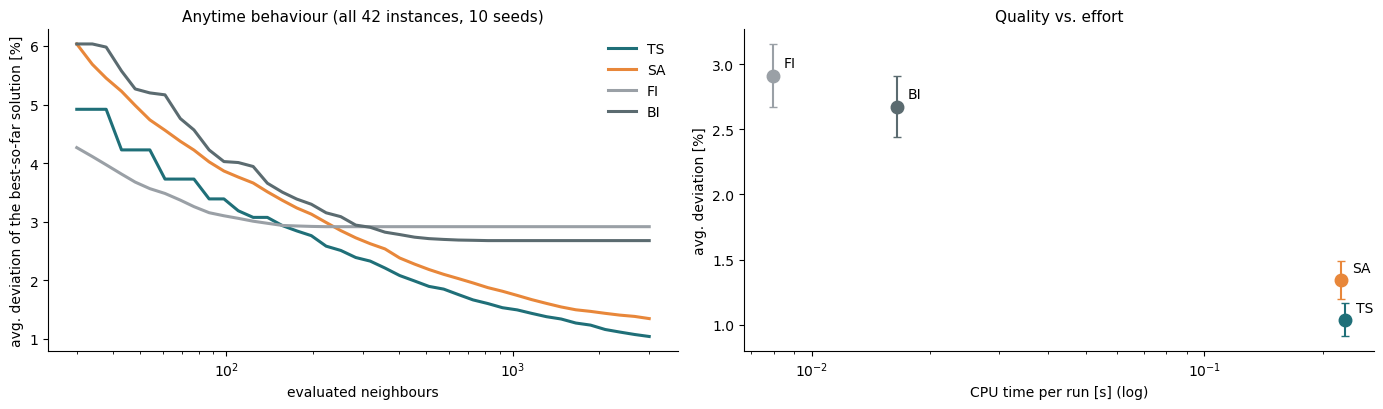

In [36]:
# anytime behaviour: average deviation of the best-so-far solution after c evaluations (FI / BI stop at their local optimum)
grid_c = np.unique(np.round(np.logspace(np.log10(30), np.log10(3000), 40)).astype(int))
anytime = {}
for a in ALGS:
    vals = []
    for c in grid_c:
        vals.append(np.mean([dev(cost_at(tr, c), BEST[nm]) for (al, nm, sd), tr in traces.items() if al == a]))
    anytime[a] = vals
fig, axs = plt.subplots(1, 2, figsize=(14, 4.2))
for a in ALGS:
    axs[0].plot(grid_c, anytime[a], label=a, color=COL[a], lw=2.2)
axs[0].set_xscale("log"); axs[0].set_xlabel("evaluated neighbours"); axs[0].set_ylabel("avg. deviation of the best-so-far solution [%]"); axs[0].legend(frameon=False)
axs[0].set_title("Anytime behaviour (all 42 instances, 10 seeds)", fontsize=11)
# quality against effort: one point per algorithm (mean over instances and seeds), the bars are the standard errors over instances
for a in ALGS:
    axs[1].errorbar(summaryE.loc[a, "CPU s / run"], summaryE.loc[a, "avg dev % (all 42)"], yerr=inst_mean[a].std() / np.sqrt(len(inst_mean)), fmt="o", ms=9, color=COL[a], capsize=3)
    axs[1].annotate(a, (summaryE.loc[a, "CPU s / run"], summaryE.loc[a, "avg dev % (all 42)"]), xytext=(8, 6), textcoords="offset points")
axs[1].set_xscale("log"); axs[1].set_xlabel("CPU time per run [s] (log)"); axs[1].set_ylabel("avg. deviation [%]"); axs[1].set_title("Quality vs. effort", fontsize=11)
for ax in axs: ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

In [37]:
# per instance set: average deviation of every algorithm
resE["group"] = resE.instance.str.extract(r"scp(\d|[a-d])")[0].str.upper()
order = ["4", "5", "6", "A", "B", "C", "D"]
resE.pivot_table(index="algorithm", columns="group", values="dev", aggfunc="mean")[order].loc[ALGS].round(2)

group,4,5,6,A,B,C,D
algorithm,,,,,,,
TS,0.68,1.23,1.86,1.16,0.36,1.16,0.86
SA,1.04,1.83,2.18,1.33,0.46,1.30,1.04
FI,1.77,2.86,3.72,1.97,3.80,2.98,4.02
BI,1.56,2.74,3.43,1.89,3.20,2.66,3.88


In [38]:
# fairness check with an equal effort: at the number of evaluations FI / BI needed, what have TS and SA reached?
rows = []
for a in ("FI", "BI"):
    c = int(round(resE[resE.algorithm == a].evals.mean()))
    rows.append({"effort of": a, "evaluations": c, "TS": np.mean([dev(cost_at(tr, c), BEST[nm]) for (al, nm, sd), tr in traces.items() if al == "TS"]),
                 "SA": np.mean([dev(cost_at(tr, c), BEST[nm]) for (al, nm, sd), tr in traces.items() if al == "SA"]), a: inst_mean[a].mean()})
pd.DataFrame(rows).set_index("effort of").round(3)

,evaluations,TS,SA,FI,BI
effort of,,,,,
FI,118,3.184,3.702,2.913,NaN
BI,246,2.506,2.872,NaN,2.675


## 15. Raw data export
The assignment asks for the **raw data used for the statistical tests** as a spreadsheet and a text file. We write

* `raw_data_NN3.xlsx` - sheets: `README`, `raw_runs` (every single run of all studies), `instance_means_final` (the matrix used for the Friedman / Wilcoxon tests of Section 14),
  `tests_final`, `SA_grid_summary`, `TS_grid_summary`, `building_blocks`, `confirmation`, `budget`;
* `raw_data_NN3.txt` - tab-separated text file with all runs (`raw_runs`) in long format, plus `raw_data_NN3_instance_means.txt` with the instance-level matrix of the final comparison.

In [39]:
studyA = resA.drop(columns=["cooling", "config"]).assign(study="A_SA_parameters")
studyB = resB.drop(columns=["fallback_share", "config"]).assign(study="B_TS_parameters")
studyC = resC.drop(columns=["level"]).assign(study="C_building_blocks")
studyD = resD.assign(study="D_budget")
studyC2 = resC2.drop(columns=["level"], errors="ignore").assign(study="C2_RE_equal_cpu")
studyF = resF.assign(study="F_confirmation_heldout")
studyE = resE.drop(columns=["group"]).assign(study="E_final_comparison")
raw = pd.concat([studyA, studyB, studyC, studyC2, studyF, studyD, studyE], ignore_index=True)
front = ["study", "algorithm", "instance", "seed", "init_cost", "final_cost", "best_known", "dev_init", "dev", "evals", "cpu_s", "cpu_init_s"]
raw = raw[front + [c for c in raw.columns if c not in front]]
print(raw.shape, "- runs per study:", raw.study.value_counts().to_dict())

readme = pd.DataFrame({"item": [
    "Assignment 3 - neighbourhood-based metaheuristics (simulated annealing, tabu search) for the SCP",
    "dev", "dev_init", "evals", "cpu_s", "dev_at_c", "study", "init", "re_step / rcl / aspiration / attr / dynamic / lam",
    "tuning vs final", "units"],
    "description": [
    "raw data of all experiments of NN3.ipynb; one row = one run of one algorithm on one instance with one seed",
    "percentage deviation of the final cost from the best known cost, 100*(final-best)/best",
    "the same for the initial solution (CH3 + RE unless 'init' says otherwise)",
    "evaluated neighbours (the budget)", "CPU (process) time of the search in seconds",
    "deviation of the best-so-far solution after c evaluations",
    "A SA grid; B TS grid; C one-factor building-block studies; C2 RE at an equal CPU time; F confirmation of candidate changes on the 28 held-out instances (seeds 201-205); D budget study; E final comparison on all 42 instances (10 seeds)",
    "initial solution: CH3+RE (default), CH3, CH1+RE",
    "building blocks of the move / tabu search (see Sections 5-7); empty = not applicable",
    "studies A-D: 14 tuning instances, seeds 101-105; study E: 42 instances, seeds 1-10, run sequentially",
    "costs as in the instance files; time in seconds"]})

testsE = pd.concat([pw.assign(test="Wilcoxon signed-rank on instance means, Holm-adjusted"),
                    pd.DataFrame([{"A": "all", "B": "all", "p": fr.pvalue, "test": "Friedman over TS, SA, FI, BI"}])], ignore_index=True)
with pd.ExcelWriter("raw_data_NN3.xlsx", engine="openpyxl") as xw:
    readme.to_excel(xw, sheet_name="README", index=False)
    raw.to_excel(xw, sheet_name="raw_runs", index=False)
    inst_mean.reset_index().to_excel(xw, sheet_name="instance_means_final", index=False)
    testsE.to_excel(xw, sheet_name="tests_final", index=False)
    tabA.to_excel(xw, sheet_name="SA_grid_summary", index=False)
    tabB.to_excel(xw, sheet_name="TS_grid_summary", index=False)
    tabC.to_excel(xw, sheet_name="building_blocks", index=False)
    tabD.to_excel(xw, sheet_name="budget", index=False)
    tabF.to_excel(xw, sheet_name="confirmation", index=False)
raw.to_csv("raw_data_NN3.txt", sep="\t", index=False)
inst_mean.reset_index().to_csv("raw_data_NN3_instance_means.txt", sep="\t", index=False)
print("written: raw_data_NN3.xlsx, raw_data_NN3.txt, raw_data_NN3_instance_means.txt")

(9548, 41) - runs per study: {'A_SA_parameters': 3024, 'C_building_blocks': 1820, 'E_final_comparison': 1680, 'B_TS_parameters': 1260, 'F_confirmation_heldout': 840, 'D_budget': 504, 'C2_RE_equal_cpu': 420}


written: raw_data_NN3.xlsx, raw_data_NN3.txt, raw_data_NN3_instance_means.txt


## 16. Interpretation and conclusions

*(All statements refer to the runs above. Deviations are percentages from the best known solutions; "pp" = percentage points. Timings vary by a few percent between runs and depend on the machine; evaluation counts do not.)*

### 16.1 Simulated annealing (Experiment A)
* **The starting temperature is the parameter that matters.** In the ANOVA (instance as block) $p_0$ has the largest effect ($\eta_p^2=0.049$; the instance explains 0.49 because instances differ in difficulty), followed by the interactions $p_0\times L$ (0.046), $p_0\times\alpha$ (0.026) and $\alpha\times L$ (0.018); the cooling ratio $\alpha$ alone is **not significant** (0.0005, $p=0.48$) and the epoch length is minor (0.003).
  Averaged over everything, $p_0\le 0.1$ gives 1.56-1.67 %, $p_0=0.3$ gives 2.20 %.
* **Why a "cold" start?** One move (drop a set and repair) changes the cost by about the cost of a whole set, so even a small $p_0$ lets SA accept large worsening moves. A hot start ($p_0=0.3$) with slow cooling ($\alpha=0.98$, $L=200$) never cools down within the budget (total cooling $\alpha^{B/L}=0.74$) and ends at 3.7 % - significantly worse than the best configuration (Holm $p=0.009$).
  The quality is a **U-shaped function of the acceptance rate** of the run: the best configurations accept about 10-15 % of the proposed moves; below 8 % the search freezes too early, above 25 % it wanders.
* **A plateau of equivalent configurations.** The best configuration ($p_0=0.01$, $\alpha=0.95$, $L=200$; 1.27 %) is statistically indistinguishable from the next five (differences $\le0.07$ pp, Holm $p=1$). SA is therefore robust as long as the start is not too hot and the total cooling is moderate; fine-tuning $\alpha$ and $L$ is not worth the effort.

### 16.2 Tabu search (Experiment B)
* **Tenure and sub-neighbourhood size both matter**, and they interact: partial $\eta^2$ = 0.33 (tenure), 0.22 ($k$), 0.18 (tenure $\times$ $k$). The best configuration is **tenure 3, $k=20$** (0.99 %).
* **Long tenures are harmful:** tenure 10 and 20 give 3.0 % and 3.7 % against 1.4-1.7 % for tenures 1-5. One move changes several sets, so a tenure of 20 iterations freezes a large part of the cover and the repair can no longer use the best sets (with tenure 20 and $k=5$ all sampled moves were even tabu in 15 % of the iterations).
  Tenures 1-3 are close (1.41-1.55 %), tenure 5 already starts to hurt (1.72 %): the optimum is a *short* tabu list.
* **$k$ trades iterations for quality of the move:** $k=5$ gives 600 iterations but a poor choice per iteration (3.4 %); $k\ge 20$ is good, and evaluating the **whole** neighbourhood is not better than a sample: averaged over the tenures it is on par with $k=20$ and $k=50$ (1.68 % vs. 1.76 % / 1.66 %), at the best tenure 3 it is clearly worse (1.47 % vs. 0.99 % for $k=20$), and it allows 2.6 times fewer iterations.

### 16.3 Building blocks (Experiments C, C2, F)
| Building block | Effect (tuning instances, 5 seeds) | Decision |
|---|---|---|
| **RE after every move** (instead of only at the end) | **+1.5 pp worse without it** (SA 2.81 % vs. 1.32 %, TS 2.68 % vs. 1.09 %; Holm $p\le0.003$), although one evaluation is about **40 % cheaper**. At an **equal CPU time** (budget scaled by the cost ratio, 5100 / 4900 evaluations) it is still +1.33 pp (SA) and +1.39 pp (TS) worse (Holm $p\le0.005$) | **keep RE on every move**: the minimal covers make costs comparable and every move more informative; the cheaper evaluation does not pay for it |
| aspiration criterion (TS) | without it +0.38 pp (Holm $p=0.028$) | keep |
| tabu attribute (TS) | `drop_only` +0.44 pp (Holm $p=0.042$) worse; `add_only` 0.24 pp better (Holm $p=0.042$); `both` is the reference | candidate (see below) |
| repair randomisation `rcl` (GRASP) | `rcl=2` better by 0.47 pp (SA) / 0.26 pp (TS), but not significant after Holm correction ($p=0.12$ / $0.15$); `rcl=3` no better | candidate (see below) |
| initial solution | random CH1 + RE is 0.5 pp worse (not significant after Holm); CH3 with and without RE are equal (RE is applied in the first move anyway) | the start matters little for a long run |
| dynamic tenure, long-term memory $\lambda$ | no effect (+0.09 pp, $\pm 0.02$ pp) | not needed for these short runs |

* **The candidates did not survive confirmation (Experiment F).** On the 28 *held-out* instances with new seeds the changes of the tuning set shrink to almost nothing: `attr=add_only` -0.07 pp (Holm $p=0.35$), `rcl=2` for TS +0.03 pp, SA `rcl=2` -0.26 pp (Holm $p=0.41$), combination -0.16 pp ($p=0.35$).
  This is the **winner's curse** of picking the best of many comparisons on the same data. No change is adopted: the **final configurations are the grid winners** (SA: $p_0=0.01$, $\alpha=0.95$, $L=200$; TS: tenure 3, $k=20$).

### 16.4 Computation budget (Experiment D)
| Budget (evaluations) | 1000 | 3000 | 10000 | 30000 |
|---|---|---|---|---|
| TS | 1.62 % | 0.99 % | 0.70 % | **0.56 %** |
| SA, schedule of the tuned configuration | 1.99 % | 1.27 % | 1.25 % | 1.25 % |
| SA, cooling scaled with the budget | 1.93 % | 1.27 % | 1.20 % | 1.03 % |
| CPU time per run | 0.09 s | 0.27 s | 0.9 s | 2.7 s |

TS keeps improving with every tripling of the budget. SA with a fixed schedule **saturates** at 3000 evaluations (it has frozen), and only a schedule that cools more slowly in proportion to the budget continues to improve - **SA must be re-tuned for a different budget, TS is less sensitive**.

### 16.5 Final comparison TS vs. SA vs. local search (Experiment E; 42 instances x 10 seeds)
| | TS | SA | BI | FI |
|---|---|---|---|---|
| average deviation (42 instances) | **1.04 %** | 1.34 % | 2.67 % | 2.91 % |
| average deviation (28 held-out instances) | **0.96 %** | 1.26 % | 2.54 % | 2.73 % |
| average of the best-of-10 runs | 0.41 % | 0.69 % | 1.23 % | 1.41 % |
| instances where the best known value was reached | **25** | 19 | 8 | 7 |
| evaluations / CPU time per run | 3000 / 0.23 s | 3000 / 0.22 s | 246 / 0.016 s | 118 / 0.008 s |

* **Statistically significant ranking TS < SA < BI < FI** (Friedman $p=2\cdot10^{-19}$, mean ranks 1.35 / 1.89 / 3.08 / 3.68; every pairwise Wilcoxon test is significant after Holm correction, $p\le 2\cdot10^{-4}$). TS beats SA on 28 instances and loses on 7 ($p=2\cdot10^{-5}$); both metaheuristics beat the local search on 38-41 of 42 instances.
* **The gain is largest on the dense instance sets B and D** (TS 0.36 % and 0.86 % against 3.2-4.0 % for the local search) where local optima are poor; the hardest set for TS and SA is 6 (1.9 % and 2.2 %).
* **Efficiency: more time, much better solutions, and more stable ones.** The metaheuristics need 14-29 times the CPU time of FI / BI, but the spread over seeds is halved (0.53 / 0.55 pp against 1.2 pp).
  At an **equal effort** the picture is nuanced: with 118 evaluations (what FI needs) FI (2.91 %) is better than TS (3.18 %) and SA (3.70 %); with 246 evaluations (BI) TS (2.51 %) is already better than BI (2.67 %) while SA (2.87 %) is not. After 100 evaluations FI is still ahead (3.09 % vs. TS 3.18 %, SA 3.84 %), after 300 evaluations both TS (2.32 %) and SA (2.67 %) have caught up with the *final* quality of FI (2.91 %) and BI (2.68 %) - the metaheuristics are worth their overhead as soon as a few hundred evaluations (about 0.02 s per run) are available.
* **Why TS beats SA here.** The drop-and-repair neighbourhood is small (about 50-90 neighbours) and its moves are large, so a *random* neighbour (SA) is usually bad (only 10-15 % are accepted) and most evaluations are wasted, whereas TS evaluates a sample of 20 neighbours and takes the **best admissible** one in every iteration: each iteration is an informed step, and the tabu list prevents cycling. SA's only guidance is the temperature.

### 16.6 Summary
1. **Both metaheuristics halve the error of the local search** (1.0-1.3 % vs. 2.7-2.9 %) with the same neighbourhood and an affordable budget (3000 evaluations, 0.25 s).
2. **Parameters:** SA - low starting temperature ($p_0\approx0.01$-0.05, acceptance rate 10-15 %), the rest is a flat plateau; TS - short tenure (2-3) and a sub-neighbourhood of about 20 neighbours; long tenures and tiny samples are bad.
3. **Building blocks:** redundancy elimination after every move is the most important one (-1.3 to -1.5 pp, also at equal CPU time); aspiration helps; the remaining variants (repair randomisation, tabu attribute, initial solution, long-term memory) gave no confirmed gain.
4. **Efficiency:** TS scales better with the budget than SA; SA needs a schedule that scales with the budget.
5. **Limitations:** one neighbourhood (drop one set); the parameters were tuned on 14 instances for a budget of 3000 evaluations (we report the 28 held-out instances separately); CPU times come from a Python implementation; richer neighbourhoods (several dropped sets, VNS-style shaking) and restarts are natural next steps.

### 16.7 Deliverables
`NN3.ipynb` (this notebook), `raw_data_NN3.xlsx` and `raw_data_NN3.txt` (+ `raw_data_NN3_instance_means.txt`) with the raw data used for all statistical tests, and the presentation `SCP_Metaheuristics.pptx`.
